# Лабораторна 2. Від сирих даних до нейромережі

У цій лабораторній роботі ви пройдете повний цикл роботи з табличним датасетом для задачі регресії — від завантаження до порівняння моделей:

- дослідницький аналіз даних (EDA): загальний огляд, гістограми, кореляції;
- обробка пропусків і викидів;
- інженерія ознак;
- baseline: множинна лінійна регресія;
- нейромережа — підбір архітектури, функцій активації, оптимізатора власними експериментами;
- чесне порівняння моделей на test за метриками регресії (MSE, RMSE, MAE, R²).

Демо-ноутбук з лекції 3-4 — основа, звертайтесь до нього як до довідника, коли щось незрозуміло. Він лежить в архіві демо-матеріалів лекції 3 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу.

## Налаштування середовища

Імпорти, фіксація seed і папки для артефактів. Моделі (`models/*.pt`), логи TensorBoard (`runs/`) і `results.csv` зберігаються на Google Drive, щоб пережити перезапуск сесії Colab. Поза Colab вони створюються поруч із ноутбуком, у тій самій структурі, що вимагається для здачі.

In [ ]:
import os
import sys
import time
import copy
import math
import random
import shutil
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.tensorboard import SummaryWriter
from IPython.display import display, Markdown

from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)


In [ ]:
SEED = 42


def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed()

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab2"
else:
    ARTIFACT_DIR = os.path.abspath(".")  # поза Colab: поруч із ноутбуком

MODELS_DIR = os.path.join(ARTIFACT_DIR, "models")
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
RESULTS_CSV = os.path.join(ARTIFACT_DIR, "results.csv")
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RUNS_DIR, exist_ok=True)

# Мережі маленькі, а весь датасет влазить у пам'ять: на GPU накладні витрати
# на пересилання перекрили б виграш, тому тренуємось на CPU (як і в лабі 1).
device = torch.device("cpu")
print("Colab:", IN_COLAB)
print("Артефакти:", ARTIFACT_DIR)
print("Пристрій :", device, "(доступний GPU:", torch.cuda.is_available(), ")")


Mounted at /content/drive
Colab: True
Артефакти: /content/drive/MyDrive/ai_systems/lab2
Пристрій : cpu (доступний GPU: False )


## 0. Опрацюйте демо-ноутбук з лекції
Прогляньте пояснення ноутбуку і запустіть всі клітинки демо-ноутбуку (крім тих секцій, в яких вказано, що їх запускати не можна).
Після цього дайте тут відповідь на запитання:
1. Чому для заповнення пропусків було обрано метод kNN?
2. Чому при тренуванні лінійної регресії train і val порівнюються лише на основі MSE, а після тренування на основі багатьох функцій? Проекспериментуйте в межах тренування з вибором функції і поділіться результатами.
3. Які висновки після клітинки 2.6 в демо Ви можете зробити?
4. Поясни для чого потрібен baseline в лінійній регресії і як він вираховується? Що є baseline для нейронної мережі?
5. Продемонструй дію всіх функцій активації на графіку функцій, згенерувавши 1000 випадкових значень Х і порахувавши для них Y через ці функції.
6. Яким чином в нейронній мережі утворилася така кількість параметрів, яка вказана після виконання 3.3?
7. Чи оптимально вибрано кількість епох в 3.5?

### 0.1 Мої відповіді:

**1. Чому для заповнення пропусків було обрано метод kNN?**

kNN-імпутація заповнює пропуск значеннями «найсхожіших» рядків: для рядка з пропуском шукаються k найближчих за відстанню по відомих ознаках сусідів, і береться середнє їхніх значень у потрібній колонці. Це краще за прості підходи з кількох причин:

- **Використовує зв'язки між ознаками.** Заповнення глобальним середнім або медіаною дає всім рядкам одне й те саме значення, а kNN оцінює пропуск з контексту: пропущену довжину велика річ отримає великою, маленька — малою.
- **Не псує розподіл.** Середнє/медіана створюють штучний пік в одній точці, зменшують дисперсію ознаки й послаблюють її кореляції з іншими. kNN бере реальні значення з реальних схожих об'єктів, тому форма розподілу й зв'язки зберігаються.
- **Без припущень про форму залежності.** На відміну від регресійної імпутації, не треба заздалегідь знати, лінійний зв'язок чи ні: достатньо метрики відстані.
- **Дешево на табличних даних помірного розміру** і легко застосовується без витоку даних: сусідів для val/test шукаємо лише серед рядків train.

Обмеження, які треба пам'ятати: ознаки потрібно **масштабувати** (інакше відстань визначатиме ознака з найбільшим масштабом), потрібно підібрати k, а на дуже великих або дуже багатовимірних даних метод повільний і гірше працює. У моєму датасеті (розділ 2.1.4) це добре видно: фізичні виміри каменя тісно пов'язані з вагою, тому сусіди за іншими вимірами дають точну оцінку пропущеного.

**2. Чому при тренуванні лінійної регресії train і val порівнюються лише за MSE, а після тренування — за багатьма метриками?**

- **MSE — це і є функція втрат, яку мінімізує градієнтний спуск.** Криві train/val за MSE показують саме те, що оптимізується, і розрив між ними (val росте, train падає) прямо вказує на перенавчання. Порівнювати train і val за «чужою» метрикою не має сенсу: це не те, що модель оптимізувала.
- **Інші метрики під час тренування нічого не додали б.** RMSE = √MSE — монотонна функція від MSE, тому має мінімум в тій самій епосі. R² = 1 − MSE/Var(y) для фіксованого набору даних — спадна лінійна функція від MSE, тож впорядковує епохи так само. Лише MAE вимірює інше (середня абсолютна помилка, менш чутлива до викидів), але диференціюється гірше й ніяк не керує градієнтом.
- **Після тренування метрики потрібні, бо вони відповідають на різні запитання:** RMSE і MAE — в одиницях таргета (зрозуміло людині, скільки «помиляємось»); MAE стійкіша до викидів, ніж RMSE (різниця між ними показує вагу великих помилок); R² безрозмірний і показує, яку частку дисперсії пояснено порівняно з прогнозом середнім (baseline).

Експеримент із вибором функції втрат (MSE / MAE / Huber) на моєму датасеті, з таблицею результатів і висновками, — у розділі **2.2.7**.

**3. Які висновки можна зробити після клітинки 2.6 демо (інтерпретація ваг лінійної моделі)?**

- Ознаки перед тренуванням стандартизовано, тож **ваги порівнянні між собою**: більший |w| означає сильніший вплив ознаки на прогноз при зміні на одне стандартне відхилення, а знак показує напрямок зв'язку. Вільний член при стандартизованому таргеті ≈ 0 (модель проходить через середнє).
- Вагу не можна читати як «причинний» вплив. Якщо ознаки корельовані, вага ділиться між ними й навіть може мати «неправильний» знак (мультиколінеарність). Тому висновки про важливість надійні лише для слабко корельованих ознак.
- Лінійна модель враховує лише **лінійний** внесок кожної ознаки: якщо справжня залежність нелінійна, вага — усереднений нахил, а решта лишається в похибці.
- Ваги дають зрозумілу точку відліку (baseline), з якою потім порівнюють нейромережу: вона може вловити нелінійності й взаємодії, але її вже не прочитаєш так просто.

Ті самі кроки з числами для мого датасету — у розділі **2.2.6**.

**4. Для чого потрібен baseline у лінійній регресії і як він обчислюється? Що є baseline для нейромережі?**

**Baseline** — це найпростіша «розумна» модель, яка задає нижню планку якості. Без неї число метрики нічого не означає: R² = 0.8 — це добре чи погано? Залежить від того, наскільки складно було б отримати його «задарма».

- **Для лінійної регресії** baseline — прогноз **середнім значенням таргета на train**: ŷ = ȳ<sub>train</sub> для будь-якого об'єкта. Його MSE дорівнює дисперсії таргета, а R² ≈ 0 (на нових даних трохи нижче нуля або поруч). Обчислення — одне середнє й порівняння з ним: модель, яка не краща за середнє, не навчилась нічого корисного з ознак.
- **Для нейромережі** baseline — те саме тривіальне середнє і, головне, **лінійна регресія** (варіант #1 цієї лаби). Нейромережа виправдана лише тоді, коли суттєво перемагає лінійну модель: додаткова складність (параметри, час навчання, гірша інтерпретованість) має «заробляти» якість.

Baseline-середнє на моїх даних обчислено в розділі **2.2.3**, лінійна модель — у **2.2.4**.

**5. Дія всіх функцій активації на графіку (1000 випадкових значень X, Y = f(X))**

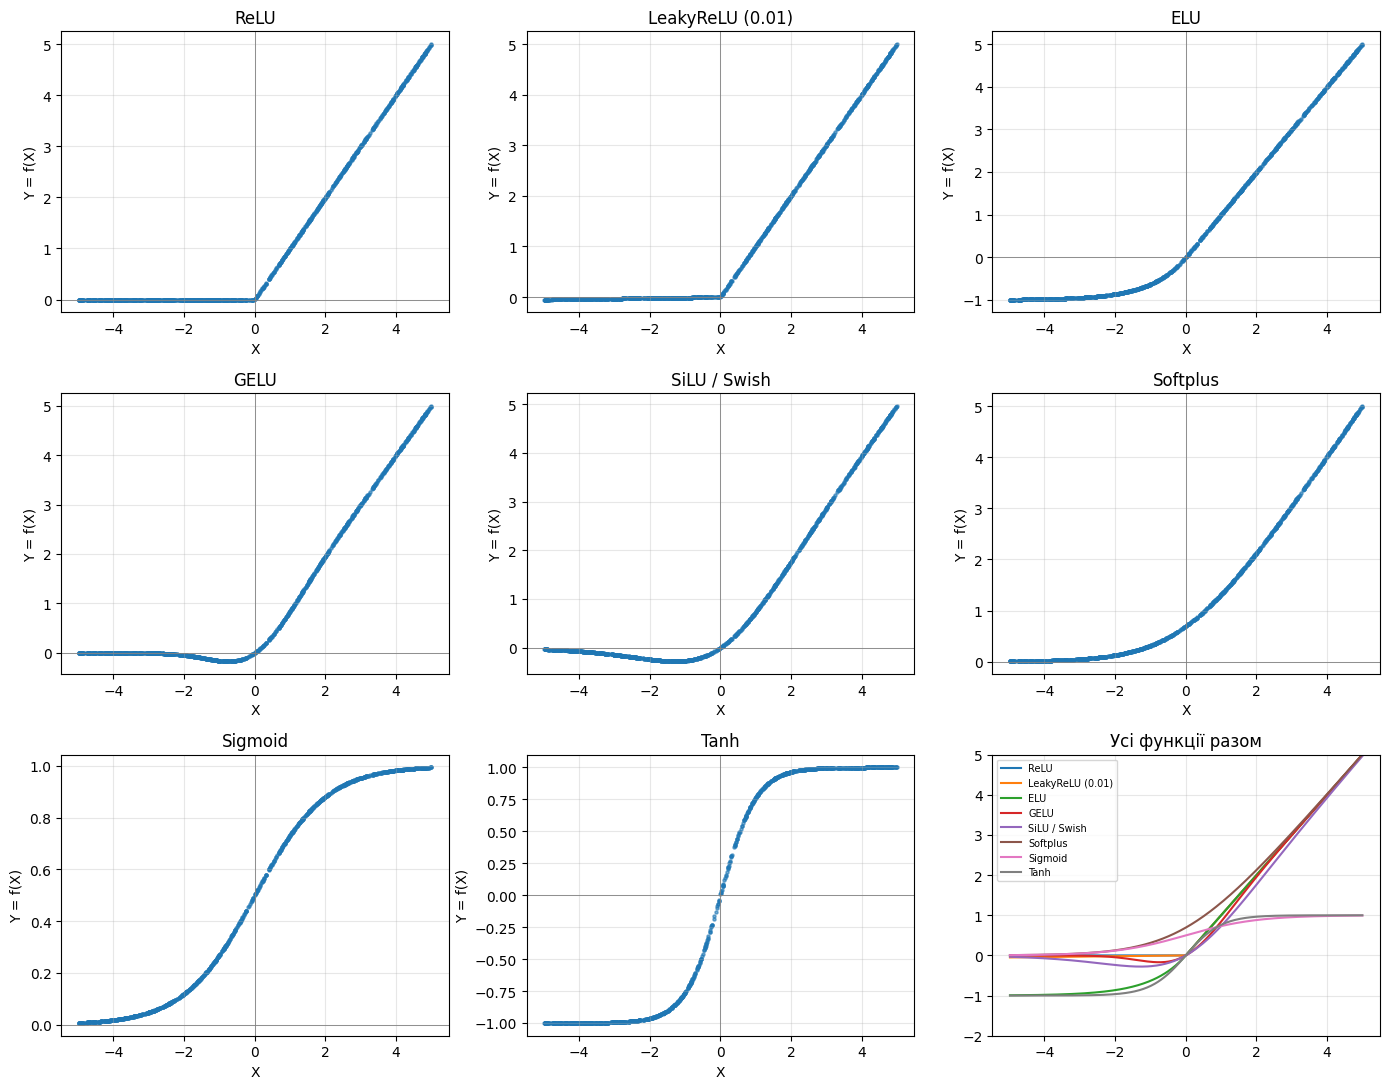

,min Y,max Y,mean Y,"частка Y<0, %"
ReLU,0.000,4.998,1.202,0.0
LeakyReLU (0.01),-0.050,4.998,1.188,52.4
ELU,-0.993,4.998,0.770,52.4
GELU,-0.170,4.998,1.151,52.4
SiLU / Swish,-0.278,4.965,1.040,52.4
Softplus,0.007,5.005,1.354,0.0
Sigmoid,0.007,0.993,0.479,0.0
Tanh,-1.000,1.000,-0.049,52.4


In [ ]:
set_seed()
x_act = torch.empty(1000).uniform_(-5, 5)  # 1000 випадкових значень X

ACT_FUNCS = {
    "ReLU": nn.ReLU(),
    "LeakyReLU (0.01)": nn.LeakyReLU(0.01),
    "ELU": nn.ELU(),
    "GELU": nn.GELU(),
    "SiLU / Swish": nn.SiLU(),
    "Softplus": nn.Softplus(),
    "Sigmoid": nn.Sigmoid(),
    "Tanh": nn.Tanh(),
}

x_np = x_act.numpy()
order = np.argsort(x_np)
act_stats = {}

fig, axes = plt.subplots(3, 3, figsize=(14, 11))
axes = axes.ravel()
for ax, (name, fn) in zip(axes, ACT_FUNCS.items()):
    y_np = fn(x_act).numpy()  # Y = f(X) для кожного з 1000 значень
    ax.scatter(x_np, y_np, s=5, alpha=0.6)
    ax.axhline(0, color="gray", lw=0.6)
    ax.axvline(0, color="gray", lw=0.6)
    ax.set_title(name)
    ax.set_xlabel("X")
    ax.set_ylabel("Y = f(X)")
    ax.grid(alpha=0.3)
    axes[8].plot(x_np[order], y_np[order], label=name)
    act_stats[name] = {"min Y": y_np.min(), "max Y": y_np.max(), "mean Y": y_np.mean(),
                       "частка Y<0, %": 100 * (y_np < 0).mean()}
axes[8].set_title("Усі функції разом")
axes[8].set_ylim(-2, 5)
axes[8].legend(fontsize=7)
axes[8].grid(alpha=0.3)
plt.tight_layout()
plt.show()

pd.DataFrame(act_stats).T.round(3)


Що видно на графіках (діапазони виходів — у таблиці вище):

| Функція | Вигляд | Коментар |
|---|---|---|
| **ReLU** | 0 при x<0, x при x≥0 | Найпростіша і найшвидша; нелінійність дає злам у нулі. Мінус: «мертві» нейрони (нульовий градієнт при x<0). |
| **LeakyReLU** | як ReLU, але зліва малий нахил 0.01·x | Лікує «мертві» нейрони: градієнт зліва не нульовий. |
| **ELU** | експоненційно згладжений лівий бік, насичується до −1 | Гладка, середнє виходів ближче до нуля; дорожча за ReLU через `exp`. |
| **GELU** | гладка «ReLU-подібна» крива з невеликим провалом при x<0 | Стандарт у трансформерах: гладка, не монотонна на від'ємній частині. |
| **SiLU / Swish** | x·sigmoid(x), гладка, з невеликим провалом при x<0 | Схожа на GELU; часто трохи краща за ReLU на глибших мережах. |
| **Softplus** | гладке наближення ReLU, завжди >0 | Диференційована всюди, але виходи лише додатні. |
| **Sigmoid** | S-подібна, виходи в (0, 1) | Насичується на краях → затухання градієнта; тепер доречна переважно на виході (ймовірності). |
| **Tanh** | S-подібна, виходи в (−1, 1), центрована в нулі | Краща за sigmoid для прихованих шарів, але теж насичується. |

Практичний висновок: ненасичувані функції (ReLU-родина, GELU, SiLU) краще передають градієнт у глибоких мережах, а насичувані (sigmoid, tanh) на краях «глушать» його. Тому в основних експериментах цієї лаби базова активація — ReLU, а Tanh використано як контрастний варіант.

**6. Як утворилася кількість параметрів, виведена після 3.3?**

Параметри мають лише шари `nn.Linear`: функції активації параметрів не мають. Лінійний шар із `in` входами та `out` виходами містить матрицю ваг `in × out` і вектор зсувів `out`:

> **params(Linear(in, out)) = in · out + out**

Загальна кількість параметрів мережі дорівнює сумі за всіма лінійними шарами; саме це число й виводить `sum(p.numel() for p in model.parameters())`. Це правило пояснює число з виводу 3.3 демо: достатньо підставити в формулу розміри шарів тієї мережі. Нижче — наочний розбір на моїй мережі `nn_v1` (6 ознак → 64 → 32 → 1):

In [ ]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


demo_net = nn.Sequential(nn.Linear(6, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))

rows = []
for name, p in demo_net.named_parameters():
    rows.append({"параметр": name, "форма": tuple(p.shape), "кількість": p.numel()})
display(pd.DataFrame(rows))

manual = (6 * 64 + 64) + (64 * 32 + 32) + (32 * 1 + 1)
print(f"За формулою in*out+out: (6·64+64) + (64·32+32) + (32·1+1) = 448 + 2080 + 33 = {manual}")
print(f"Підрахунок у PyTorch   : {count_params(demo_net)}")
assert manual == count_params(demo_net)


,параметр,форма,кількість
0,0.weight,"(64, 6)",384
1,0.bias,"(64,)",64
2,2.weight,"(32, 64)",2048
3,2.bias,"(32,)",32
4,4.weight,"(1, 32)",32
5,4.bias,"(1,)",1


За формулою in*out+out: (6·64+64) + (64·32+32) + (32·1+1) = 448 + 2080 + 33 = 2561
Підрахунок у PyTorch   : 2561


**7. Чи оптимально вибрано кількість епох у 3.5?**

Оптимальність кількості епох перевіряється за **кривою val-втрат**, а не за train:

- якщо val ще **спадає** до кінця тренування — епох замало (недотренування), можна продовжувати;
- якщо val досягла мінімуму **значно раніше за кінець**, а далі росте при падінні train — епох забагато (перенавчання), корисні ранній зупин (early stopping) або відкат до ваг із найкращої епохи;
- якщо val давно на плато, а модель усе ще тренується, зайві епохи лише марнують час.

Тому кількість епох — не «магічне число», а гіперпараметр, який підбирають за val-кривою. Саме так зроблено в моїх експериментах: для кожного прогону зберігається **найкраща за val епоха** (ваги відкочуються до неї), а в розділі **2.4** є таблиця «епоха мінімуму val / усього епох» і окремий варіант із більшою кількістю епох — вона й відповідає, чи вистачало епох. Для демо-ноутбука висновок робиться за тим самим критерієм: подивитися на val-криву з 3.5 і порівняти положення її мінімуму з кінцем тренування.

---
## 1. Датасети

Ви отримаєте один з 10 датасетів нижче. Усі — задачі регресії на Hugging Face: табличні дані, здебільшого числові ознаки, від кількасот до кількадесяти тисяч рядків.

1. **[King County House Sales](https://huggingface.co/datasets/kraina/house_sales_in_king_county)** — 21 613 продажів будинків (Вашингтон, 2014–2015). Таргет: `price`. ⚠️ `load_dataset("kraina/house_sales_in_king_county")` не працює (застарілий loading-скрипт) — вантажте напряму: `load_dataset("parquet", data_files="https://huggingface.co/datasets/kraina/house_sales_in_king_county/resolve/main/data/house_sales_king_county.parquet")`.
2. **[Diamonds](https://huggingface.co/datasets/jdxcosta/diamonds)** — 53 940 діамантів. Таргет: `price`. Ознаки: вага (`carat`), огранка, колір, чистота, розміри.
3. **[Concrete Compressive Strength](https://huggingface.co/datasets/foundry-ml/dataset_concrete_compressive_strength)** — 1 030 замісів бетону. Таргет: міцність на стиск. Усі ознаки числові (склад суміші + вік).
4. **[Auto MPG](https://huggingface.co/datasets/scikit-learn/auto-mpg)** — 398 автомобілів. Таргет: `mpg` (витрата пального). Найменший і найпростіший датасет зі списку.
5. **[Wine Quality](https://huggingface.co/datasets/codesignal/wine-quality)** — 1 599 (червоне) + 4 898 (біле) вин. Таргет: `quality` (оцінка 3–9). Усі ознаки — хімічний склад, числові.
6. **[Laptop Price](https://huggingface.co/datasets/Ammok/laptop_price_prediction)** — 977 + 325 ноутбуків. Таргет: `Price`. Частина ознак текстові (`RAM`, `Storage`, `CPU`) — доведеться парсити в числа.
7. **[Bike Sharing Demand](https://huggingface.co/datasets/t22000t/bike-sharing-tabular)** — 17 379 годинних записів прокату велосипедів. Таргет: `cnt`. Часові й погодні ознаки.
8. **[Ames House Prices](https://huggingface.co/datasets/t22000t/house-prices-tabular)** — 1 460 будинків, 79 ознак. Таргет: `SalePrice`. Найбільше категоріальних ознак зі списку — гарна практика на encoding.
9. **[Medical Insurance Cost](https://huggingface.co/datasets/harishsohani/medical-insurance-cost-prediction)** — 1 338 застрахованих. Таргет: `charges`. Компактний, мало ознак — хороший старт, якщо часу мало. ⚠️ У репозиторії кілька CSV одразу (`Xtrain`/`Xtest`/`insurance.csv`) — вкажіть файл явно: `load_dataset("harishsohani/medical-insurance-cost-prediction", data_files="insurance.csv")`.
10. **[Abalone](https://huggingface.co/datasets/mstz/abalone)** — 4 177 молюсків. Таргет: `number_of_rings` (вік). Усі ознаки — фізичні виміри, окрім `sex`.

Решта (2–5, 7–8, 10) вантажаться напряму — `load_dataset("<repo_id>")` без додаткових аргументів, HF-токен не потрібен.

### 1.1. Який датасет мій?

Визначте самі власний датасет: беремо Ваше ПІБ, рахуємо SHA-256 хеш, залишок від ділення на 10 — це індекс у списку датасетів вище (0 → перший, 9 → останній).

**Формат ПІБ:** точно як у списку групи — `Прізвище Ім'я По-батькові`, по одному пробілу між словами, без зайвих пробілів на початку/в кінці. Якщо використаєте інший формат - **не зарахую лабу**!!!

In [ ]:
import hashlib

DATASETS = [
    "King County House Sales",
    "Diamonds",
    "Concrete Compressive Strength",
    "Auto MPG",
    "Wine Quality",
    "Laptop Price",
    "Bike Sharing Demand",
    "Ames House Prices",
    "Medical Insurance Cost",
    "Abalone",
]

FULL_NAME = "Патлай Максим Васильович"  # ПІБ точно як у списку групи

dataset_index = int(hashlib.sha256(FULL_NAME.encode("utf-8")).hexdigest(), 16) % len(DATASETS)
print(f"Ваш датасет (#{dataset_index + 1}):", DATASETS[dataset_index])

Ваш датасет (#2): Diamonds


---
## 2. Що потрібно зробити

Нижче — загальний план роботи, без коду: код і пояснення до кожного кроку дивіться в **демо-ноутбуці лекції 3-4**, номери розділів позначені в дужках. Ваша задача — повторити той самий підхід на своєму датасеті, а не скопіювати код один в один: у вашого датасету інші колонки, інші типи пропусків (чи їх взагалі нема), інші викиди (чи їх нема) — рішення на кожному кроці обґрунтовуйте під свої дані, а не тому, що "так було в демо".

### 2.1. Підготовка даних

1. Завантажте свій датасет (демо 1.1) і перетворіть на `pandas.DataFrame` (1.2).
2. Зробіть спліт **train / val / test** одразу, до будь-якого аналізу (1.3) — і поясніть своїми словами, чому саме в такому порядку (нагадування: data leakage).
3. Загальний огляд (`head`/`info`/`describe`, 1.4).
4. Обробка пропусків (1.5) — **якщо вони є**. Немає пропусків — так і напишіть, це теж валідний результат, не треба їх штучно вигадувати.
5. EDA (1.6): хоча б гістограми і кореляційна матриця. Що впадає в очі у ваших даних — capping, скошені розподіли, мультиколінеарність?
6. Обробка викидів (1.7) — **за потреби**, з обґрунтуванням: звідки взявся викид і чому саме таке рішення (видалити / трансформувати / залишити).
7. Інженерія ознак (1.8) — **за потреби**: чи є сенс комбінувати/прибирати ознаки з високою кореляцією між собою.

### 2.2. Baseline: множинна лінійна регресія

Стандартизація ознак (2.1), тензори (2.2), тренування `nn.Linear` (2.3), крива навчання (2.4), метрики на test — MSE/RMSE/MAE/R² (2.5), інтерпретація ваг (2.6).

Це ваш **варіант #1**, точка відліку для всього, що далі.

### 2.3. Нейромережа: щонайменше 2 різні архітектури

За зразком розділу 3 демо: `nn.Sequential` з прихованими шарами, ReLU, оптимізатор Adam.

Спробуйте **мінімум 2 архітектури**, які відрізняються не косметично — напр. різна кількість шарів, різна ширина шарів, чи інша функція активації (3.2). Кожна — окремий варіант.

### 2.4. Підбір гіперпараметрів: щонайменше 3 зміни

Візьміть архітектуру, яка показала себе краще, і поекспериментуйте з гіперпараметрами: learning rate, оптимізатор (SGD/Adam), кількість епох, розмір batch (якщо вирішите його ввести) тощо. Змінюйте **по одному параметру за раз** — інакше не зрозумієте, що саме вплинуло на результат.

**Разом (2.2 + 2.3 + 2.4):** щонайменше 5 варіантів моделі (1 лінійна + 2 архітектури + 2 гіперпараметри), до **10 варіантів** — якщо є час і бажання поекспериментувати більше, це тільки заохочується.

### 2.5. Логування і порівняння

Кожен варіант (2.2-2.4) логуйте в TensorBoard в окрему підпапку `RUNS_DIR` (як у 2.3/3.5 демо) — з осмисленою назвою (`linear`, `nn_v1_2layers`, `nn_v2_deeper`, `nn_v2_lr_0.001`, ...), щоб потім усі криві можна було накласти одна на одну (3.8 демо) і візуально порівняти.

Наприкінці зведіть усі варіанти в одну таблицю (модель → MSE/RMSE/MAE/R² на test) і дайте коротку письмову відповідь:
- Яка модель перемогла і наскільки суттєво?
- Чи виправдала себе нейромережа порівняно з лінійною регресією на вашому датасеті?
- Що з ваших змін (архітектура чи гіперпараметри) дало найбільший ефект?

---
# Виконання

Мій датасет — **Diamonds** (53 940 діамантів, задача регресії: передбачити `price`). Ознаки: вага `carat`, огранка `cut`, колір `color`, чистота `clarity`, пропорції `depth` і `table` та три лінійні виміри `x`, `y`, `z` (мм).

## 2.1. Підготовка даних

### 2.1.1. Завантаження датасету та константи

Усі «знання про домен» зібрано в одному місці: назви колонок і природний порядок якості категоріальних ознак. `cut`, `color` і `clarity` — не просто мітки, а **порядкові** шкали (від гіршого до кращого); колір кодується від J (найгірший) до D (безбарвний, найкращий).

In [ ]:
TARGET = "price"
DIM_COLS = ["x", "y", "z"]
CAT_COLS = ["cut", "color", "clarity"]
NUM_COLS = ["carat", "depth", "table", "x", "y", "z", "price"]

# Природний порядок якості (від гіршого до кращого)
CUT_ORDER = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
COLOR_ORDER = ["J", "I", "H", "G", "F", "E", "D"]  # D -- безбарвний (найкращий), J -- найгірший
CLARITY_ORDER = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]
ORDERINGS = {"cut": CUT_ORDER, "color": COLOR_ORDER, "clarity": CLARITY_ORDER}

# Фізичні межі розмірів: найбільший камінь у даних (≈5 карат) має x ≈ 10.7 мм,
# тож усе, що суттєво перевищує ці межі -- помилка введення, а не діамант.
MAX_XY_MM, MAX_Z_MM = 15.0, 10.0
KNN_COLS = ["carat", "depth", "table", "x", "y", "z"]  # ознаки, за якими шукаємо сусідів
CLIP_COLS = ["depth", "table"]                         # ознаки для winsorization


In [ ]:
try:
    from datasets import load_dataset
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "datasets"])
    from datasets import load_dataset

ds = load_dataset("jdxcosta/diamonds")
print(ds)

# беремо всі спліти (на HF він один -- train) і склеюємо в один DataFrame
df_raw = pd.concat([ds[name].to_pandas() for name in ds.keys()], ignore_index=True)

# «Unnamed: 0» -- службовий індекс pandas, а не властивість діаманта. Залишити його
# як ознаку не можна: він не має фізичного змісту, а модель могла б «навчитись» на порядку рядків.
index_cols = [c for c in df_raw.columns if str(c).startswith("Unnamed")]
df_raw = df_raw.drop(columns=index_cols)

# ціна іноді читається як текст із роздільниками тисяч ("2,757")
if df_raw[TARGET].dtype == object:
    df_raw[TARGET] = pd.to_numeric(df_raw[TARGET].astype(str).str.replace(",", ""), errors="coerce")

# категорії мають збігатися з очікуваними порядками -- інакше кодування дасть NaN
for col, order in ORDERINGS.items():
    unknown = set(df_raw[col].unique()) - set(order)
    if unknown:
        print(f"УВАГА: у колонці {col} є невідомі значення: {unknown}")

print("Видалено службові колонки:", index_cols)
print("Розмір датасету:", df_raw.shape)
df_raw.head()


diamonds.csv:   0%|          | 0.00/3.19M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/53940 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['Unnamed: 0', 'carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y', 'z'],
        num_rows: 53940
    })
})
Видалено службові колонки: ['Unnamed: 0']
Розмір датасету: (53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


### 2.1.2. Спліт train / val / test — **до** будь-якого аналізу

Спліт 70 / 15 / 15 робимо одразу після завантаження, ще до перегляду даних, і пояснюю чому. Майже все, що ми робимо на наступних кроках, **навчається на даних**: середнє й std для стандартизації, сусіди для kNN-імпутації, межі для викидів, висновки з кореляцій про те, які ознаки залишити, навіть вибір архітектури за кривою втрат. Якщо ці статистики порахувати на всьому датасеті, інформація про val/test «просочується» в підготовку даних і в модель ще до тренування (**data leakage**). Тоді val/test перестають бути «невидимими», а метрики виходять завищеними й нечесними.

Тому порядок такий: **спліт → усе, що навчається («fit»), лише на train → до val/test застосовуємо вже готові перетворення («transform»)**. Val використовуємо для вибору архітектури/гіперпараметрів, а test — лише для фінального звіту.

In [ ]:
def split_frame(df, train_frac=0.70, val_frac=0.15, seed=SEED):
    """Випадковий (перемішаний) спліт на train/val/test."""
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(df))
    n_tr, n_va = round(train_frac * len(df)), round(val_frac * len(df))
    parts = (idx[:n_tr], idx[n_tr:n_tr + n_va], idx[n_tr + n_va:])
    return tuple(df.iloc[p].reset_index(drop=True) for p in parts)


train_df, val_df, test_df = split_frame(df_raw)
print(f"train/val/test: {len(train_df)} / {len(val_df)} / {len(test_df)}  (разом {len(df_raw)})")
# від цього моменту ВЕСЬ аналіз -- лише на train_df


train/val/test: 37758 / 8091 / 8091  (разом 53940)


### 2.1.3. Загальний огляд (тільки train)

In [ ]:
display(train_df.head())
train_df.info()
display(train_df[NUM_COLS].describe().T.round(3))
display(train_df[CAT_COLS].describe())

# дублікати: рядки, що повторюються в train, та тестові рядки, які точно збігаються з train
n_dup_train = int(train_df.duplicated().sum())
cross_dups = len(test_df.merge(train_df.drop_duplicates(), on=list(train_df.columns), how="inner"))
print(f"\nДублікатів усередині train: {n_dup_train} ({100 * n_dup_train / len(train_df):.2f}%)")
print(f"Рядків test, що точно збігаються з рядком train: {cross_dups} ({100 * cross_dups / len(test_df):.2f}%)")


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.74,Ideal,I,VS1,61.1,57.0,2947,5.83,5.86,3.57
1,0.53,Ideal,F,VVS1,61.4,57.0,2834,5.20,5.23,3.20
2,1.21,Very Good,H,VS2,62.9,55.0,7426,6.75,6.80,4.26
3,0.32,Ideal,E,VVS2,61.2,57.0,729,4.38,4.41,2.69
4,1.29,Ideal,H,SI2,61.6,54.0,6300,7.00,7.02,4.32


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37758 entries, 0 to 37757
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    37758 non-null  float64
 1   cut      37758 non-null  object 
 2   color    37758 non-null  object 
 3   clarity  37758 non-null  object 
 4   depth    37758 non-null  float64
 5   table    37758 non-null  float64
 6   price    37758 non-null  int64  
 7   x        37758 non-null  float64
 8   y        37758 non-null  float64
 9   z        37758 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 2.9+ MB


,count,mean,std,min,25%,50%,75%,max
carat,37758.0,0.799,0.474,0.2,0.40,0.70,1.04,5.01
depth,37758.0,61.746,1.433,43.0,61.00,61.80,62.50,79.00
table,37758.0,57.463,2.239,43.0,56.00,57.00,59.00,95.00
x,37758.0,5.733,1.124,0.0,4.71,5.70,6.54,10.74
y,37758.0,5.736,1.124,0.0,4.72,5.71,6.54,31.80
z,37758.0,3.540,0.711,0.0,2.91,3.53,4.04,31.80
price,37758.0,3943.612,3996.340,326.0,949.00,2404.00,5340.75,18818.00


,cut,color,clarity
count,37758,37758,37758
unique,5,7,8
top,Ideal,G,SI1
freq,15101,7944,9155



Дублікатів усередині train: 80 (0.21%)
Рядків test, що точно збігаються з рядком train: 19 (0.23%)


Дублікатів дуже мало, а збіг характеристик не означає помилку: різні камені цілком можуть мати однакові виміри, пропорції й ціну. Тож рядки **залишаємо**: вилучення нічого суттєво не змінило б, а випадкові збіги між train і test вносять лише мізерне завищення метрик.

### 2.1.4. Пропуски

Спершу шукаємо **явні** пропуски (`NaN`), потім **приховані**: значення, які формально присутні, але фізично неможливі. Діамант не може мати нульову ширину, довжину чи висоту, тож `0` у `x`, `y`, `z` — це закодований пропуск.

In [ ]:
print("Явні пропуски (NaN) у train:")
print(train_df.isna().sum().to_string())

zero_counts = (train_df[DIM_COLS] <= 0).sum()
print("\nНулі (неможливі значення) у вимірах train:")
print(zero_counts.to_string())
print(f"Рядків із хоча б одним нульовим виміром: {int((train_df[DIM_COLS] <= 0).any(axis=1).sum())}")

display(train_df[(train_df[DIM_COLS] <= 0).any(axis=1)].head(10))


Явні пропуски (NaN) у train:
carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0

Нулі (неможливі значення) у вимірах train:
x     7
y     6
z    13
Рядків із хоча б одним нульовим виміром: 13


,carat,cut,color,clarity,depth,table,price,x,y,z
2408,1.14,Fair,G,VS1,57.5,67.0,6381,0.00,0.00,0.0
8719,2.80,Good,G,SI2,63.8,58.0,18788,8.90,8.85,0.0
13465,0.71,Good,F,SI2,64.1,60.0,2130,0.00,0.00,0.0
13709,1.10,Premium,G,SI2,63.0,59.0,3696,6.50,6.47,0.0
17344,1.15,Ideal,G,VS2,59.2,56.0,5564,6.88,6.83,0.0
17368,2.02,Premium,H,VS2,62.7,53.0,18207,8.02,7.95,0.0
21013,1.50,Good,G,I1,64.0,61.0,4731,7.15,7.04,0.0
21737,1.00,Very Good,H,VS2,63.3,53.0,5139,0.00,0.00,0.0
24555,1.20,Premium,D,VVS1,62.1,59.0,15686,0.00,0.00,0.0
25583,1.12,Premium,G,I1,60.4,59.0,2383,6.71,6.67,0.0


**Висновок.** Явних пропусків немає, і це валідний результат: штучно їх вигадувати не потрібно. Проте колонки `x`, `y`, `z` містять нулі: це **приховані пропуски** (датчик/запис не зафіксував розмір). Таких рядків дуже мало, тож видалення нічого б не зекономило, але змарнувало б решту інформації в цих рядках (вага, чистота, ціна).

**Рішення:** вважати такі нулі пропусками (`NaN`) і заповнити їх **kNN-імпутацією**, як у демо. Це доречно, бо виміри каменя майже детерміновано пов'язані з вагою (`carat`), `depth` і `table`: сусіди за цими ознаками дадуть точну оцінку. Імпутер навчається **лише на train**, а до val/test застосовується вже готовим (розділ 2.1.7).

### 2.1.5. EDA: розподіли, категорії, кореляції

Починаю з гістограм усіх числових ознак (кінці обрізано по 0.1-му й 99.9-му процентилях, щоб кілька екстремальних значень не стискали графік) та логарифма ціни.

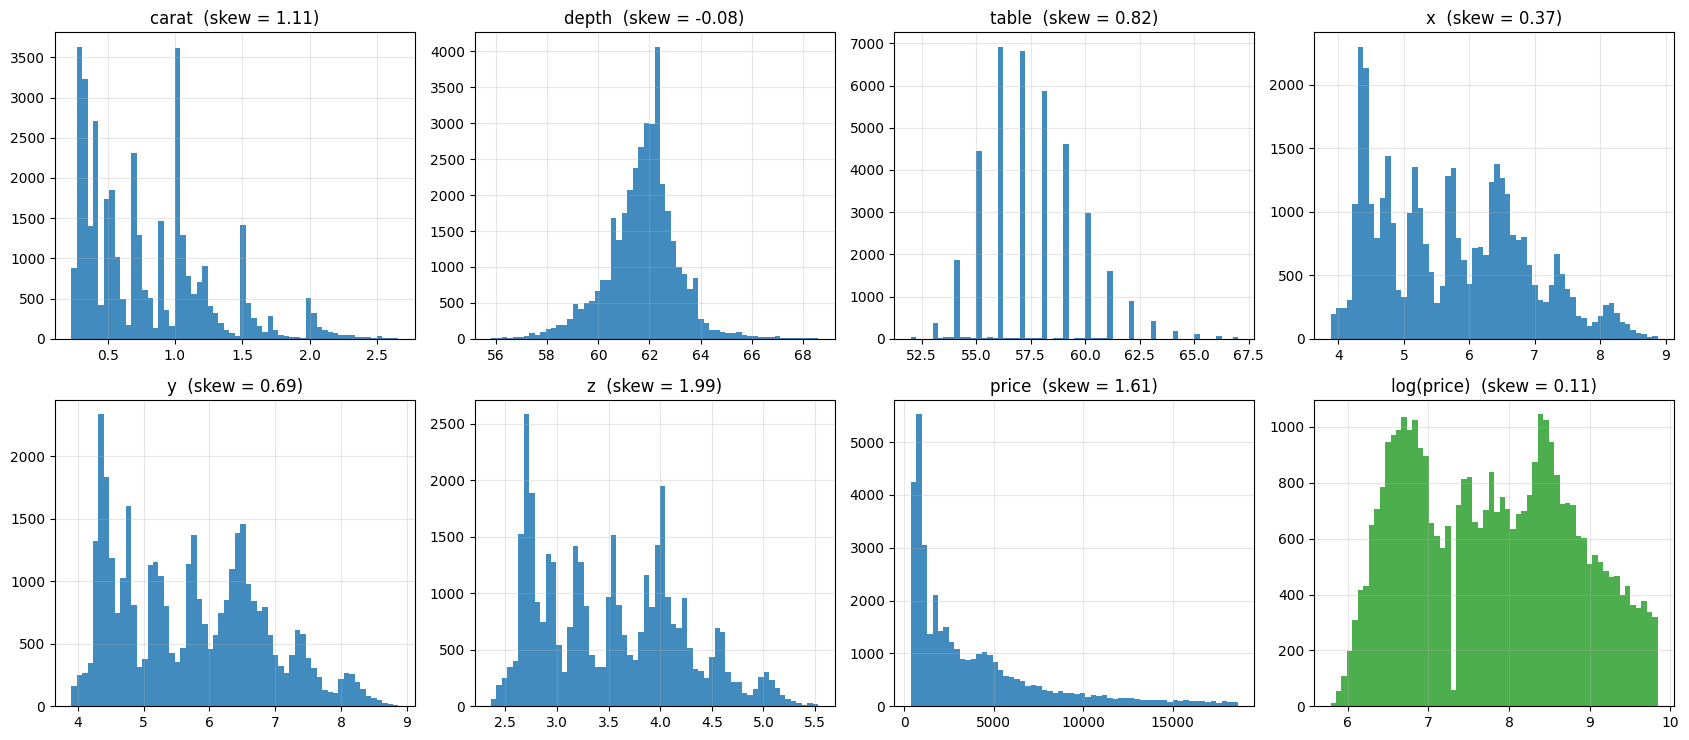

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
axes = axes.ravel()
for ax, col in zip(axes, NUM_COLS):
    s = train_df[col]
    lo, hi = s.quantile([0.001, 0.999])
    ax.hist(s[(s >= lo) & (s <= hi)], bins=60, color="C0", alpha=0.85)
    ax.set_title(f"{col}  (skew = {s.skew():.2f})")
    ax.grid(alpha=0.3)
axes[7].hist(np.log(train_df[TARGET]), bins=60, color="C2", alpha=0.85)
axes[7].set_title(f"log(price)  (skew = {np.log(train_df[TARGET]).skew():.2f})")
axes[7].grid(alpha=0.3)
plt.tight_layout()
plt.show()


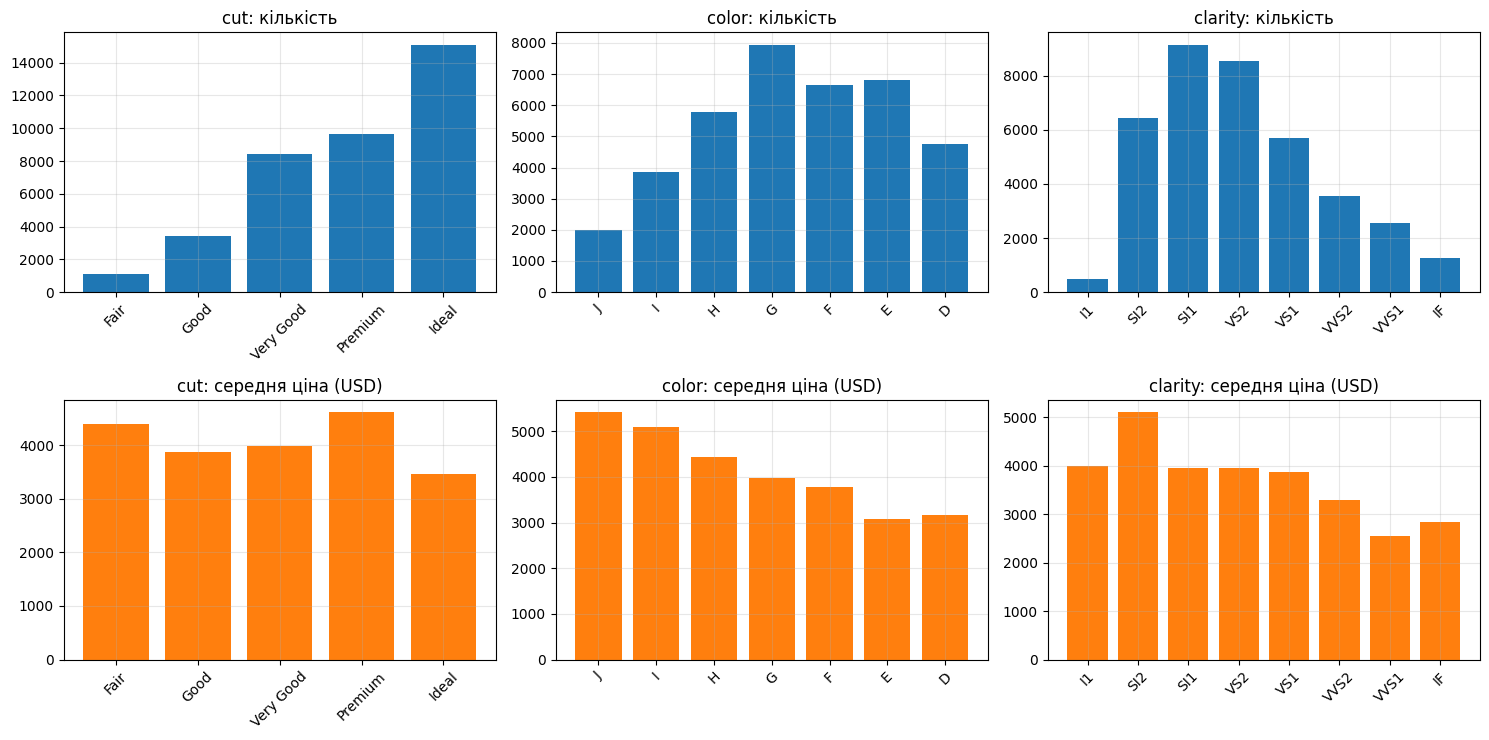

cut -> {'Fair': 4397.0, 'Good': 3880.0, 'Very Good': 3987.0, 'Premium': 4618.0, 'Ideal': 3469.0}
color -> {'J': 5419.0, 'I': 5104.0, 'H': 4447.0, 'G': 3978.0, 'F': 3786.0, 'E': 3086.0, 'D': 3165.0}
clarity -> {'I1': 3989.0, 'SI2': 5105.0, 'SI1': 3962.0, 'VS2': 3950.0, 'VS1': 3871.0, 'VVS2': 3285.0, 'VVS1': 2551.0, 'IF': 2836.0}


In [ ]:
# Категоріальні ознаки: скільки діамантів у кожній категорії і яка середня ціна
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
cat_summary = {}
for j, (col, order) in enumerate(ORDERINGS.items()):
    g = train_df.groupby(col)[TARGET].agg(["count", "mean"]).reindex(order)
    cat_summary[col] = g
    axes[0, j].bar(order, g["count"], color="C0")
    axes[0, j].set_title(f"{col}: кількість")
    axes[1, j].bar(order, g["mean"], color="C1")
    axes[1, j].set_title(f"{col}: середня ціна (USD)")
    for ax in (axes[0, j], axes[1, j]):
        ax.tick_params(axis="x", rotation=45)
        ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
for col, g in cat_summary.items():
    print(col, "->", g["mean"].round(0).to_dict())


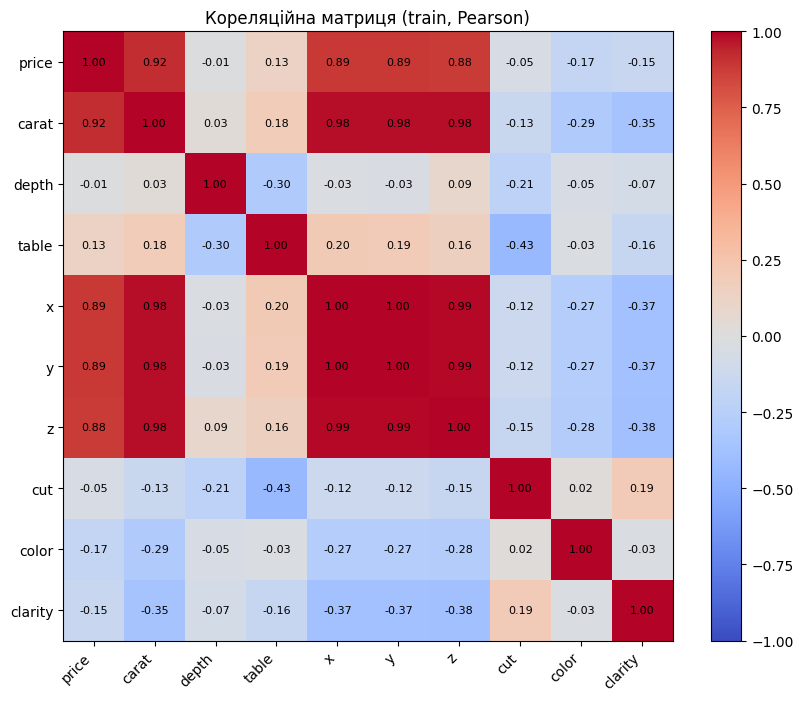

Найсильніші попарні кореляції:


,ознака_1,ознака_2,r,|r|
30,x,y,0.999,0.999
31,x,z,0.991,0.991
35,y,z,0.991,0.991
11,carat,x,0.978,0.978
12,carat,y,0.977,0.977
13,carat,z,0.977,0.977
0,price,carat,0.921,0.921
4,price,y,0.889,0.889
3,price,x,0.887,0.887
5,price,z,0.882,0.882


In [ ]:
def encode_ordinals(df, orderings=None):
    """Заміна категорій порядковими номерами 0..k-1 (більше = краща якість)."""
    orderings = orderings or ORDERINGS
    out = df.copy()
    for col, order in orderings.items():
        out[col] = out[col].map({v: i for i, v in enumerate(order)})
    return out


def mark_invalid_dims(df):
    """Фізично неможливі виміри (<=0 або значно більші за будь-який реальний камінь) -> NaN."""
    out = df.copy()
    for col, cap in [("x", MAX_XY_MM), ("y", MAX_XY_MM), ("z", MAX_Z_MM)]:
        bad = (out[col] <= 0) | (out[col] > cap)
        out.loc[bad, col] = np.nan
    return out


def plot_corr(corr, title):
    fig, ax = plt.subplots(figsize=(8.5, 7))
    im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)))
    ax.set_xticklabels(corr.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(corr)))
    ax.set_yticklabels(corr.index)
    for i in range(len(corr)):
        for j in range(len(corr)):
            ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
    fig.colorbar(im, ax=ax)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


# Кореляції рахуємо без рядків із некоректними вимірами: кілька нулів і екстремальних
# значень спотворили б коефіцієнти. Категорії кодуємо порядковими номерами.
eda = encode_ordinals(mark_invalid_dims(train_df).dropna(subset=DIM_COLS))
corr_cols = ["price", "carat", "depth", "table", "x", "y", "z", "cut", "color", "clarity"]
corr = eda[corr_cols].corr()
plot_corr(corr, "Кореляційна матриця (train, Pearson)")

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs = upper.rename("r").reset_index()
pairs.columns = ["ознака_1", "ознака_2", "r"]
pairs["|r|"] = pairs["r"].abs()
print("Найсильніші попарні кореляції:")
display(pairs.sort_values("|r|", ascending=False).head(10).round(3))


In [ ]:
# Автоматичний підсумок EDA: усі числа беруться з даних вище
price = train_df[TARGET]
top_price_corr = corr["price"].drop("price").sort_values(key=np.abs, ascending=False)
strong_pairs = pairs[(pairs["|r|"] > 0.9) & (~pairs[["ознака_1", "ознака_2"]].isin([TARGET]).any(axis=1))]
neg_quality = [c for c in CAT_COLS if corr.loc["price", c] < 0]

lines = ["**Що впадає в очі:**", ""]
lines.append(f"- **Скошений таргет.** Ціна має довгий правий хвіст: середня ({price.mean():.0f} USD) значно вища за медіану "
             f"({price.median():.0f} USD), асиметрія {price.skew():.2f}. Після логарифмування асиметрія падає до "
             f"{np.log(price).skew():.2f}. Отже, великих і дорогих каменів мало, але вони задають значну частину помилки MSE.")
lines.append(f"- **Головний чинник ціни — вага.** Найсильніша кореляція з ціною у `{top_price_corr.index[0]}` "
             f"(r = {top_price_corr.iloc[0]:.2f}); далі `{top_price_corr.index[1]}` (r = {top_price_corr.iloc[1]:.2f}).")
lines.append(f"- **Мультиколінеарність.** Пар ознак із |r| > 0.9: {len(strong_pairs)}; "
             + ", ".join(f"`{a}`–`{b}` ({r:.2f})" for a, b, r in strong_pairs[["ознака_1", "ознака_2", "r"]].head(6).itertuples(index=False))
             + ". Вага та три лінійні виміри описують практично одне й те саме (розмір каменя).")
if neg_quality:
    lines.append("- **Парадокс якості.** Для " + ", ".join(f"`{c}`" for c in neg_quality)
                 + " кореляція між «кращою» категорією та ціною **від'ємна** (див. середні ціни за категоріями). Це не означає, "
                   "що якість здешевлює камінь: кращі за кольором/чистотою камені в середньому **менші**, а ціну визначає вага (конфаундер). "
                   "Лінійна модель, що бачить `carat`, має відділити ці ефекти (перевіримо у 2.2.6).")
lines.append(f"- **Приховані пропуски й екстремальні виміри.** Нулі у `x`/`y`/`z` вже знайдено (2.1.4); максимум `y` у train — "
             f"{train_df['y'].max():.1f} мм, `z` — {train_df['z'].max():.1f} мм, хоча найбільший реальний камінь має "
             f"x ≈ {train_df['x'].max():.1f} мм. Такі значення неможливі для каменя цієї ваги (розбираємо в 2.1.6).")
display(Markdown("\n".join(lines)))


**Що впадає в очі:**

- **Скошений таргет.** Ціна має довгий правий хвіст: середня (3944 USD) значно вища за медіану (2404 USD), асиметрія 1.61. Після логарифмування асиметрія падає до 0.11. Отже, великих і дорогих каменів мало, але вони задають значну частину помилки MSE.
- **Головний чинник ціни — вага.** Найсильніша кореляція з ціною у `carat` (r = 0.92); далі `y` (r = 0.89).
- **Мультиколінеарність.** Пар ознак із |r| > 0.9: 6; `carat`–`x` (0.98), `carat`–`y` (0.98), `carat`–`z` (0.98), `x`–`y` (1.00), `x`–`z` (0.99), `y`–`z` (0.99). Вага та три лінійні виміри описують практично одне й те саме (розмір каменя).
- **Парадокс якості.** Для `cut`, `color`, `clarity` кореляція між «кращою» категорією та ціною **від'ємна** (див. середні ціни за категоріями). Це не означає, що якість здешевлює камінь: кращі за кольором/чистотою камені в середньому **менші**, а ціну визначає вага (конфаундер). Лінійна модель, що бачить `carat`, має відділити ці ефекти (перевіримо у 2.2.6).
- **Приховані пропуски й екстремальні виміри.** Нулі у `x`/`y`/`z` вже знайдено (2.1.4); максимум `y` у train — 31.8 мм, `z` — 31.8 мм, хоча найбільший реальний камінь має x ≈ 10.7 мм. Такі значення неможливі для каменя цієї ваги (розбираємо в 2.1.6).

### 2.1.6. Викиди

Для кожного числового стовпця рахую межі за правилом Тьюкі (Q1 − 1.5·IQR, Q3 + 1.5·IQR) і дивлюсь на кількість точок поза ними. Але автоматично викидати «все поза межами» не можна: потрібно зрозуміти **походження** кожного викиду.

,нижня межа,верхня межа,викидів,"частка, %",min,max
колонка,,,,,,
carat,-0.560,2.000,1333,3.530,0.2,5.01
depth,58.750,64.750,1791,4.743,43.0,79.00
table,51.500,63.500,432,1.144,43.0,95.00
x,1.965,9.285,23,0.061,0.0,10.74
y,1.990,9.270,19,0.050,0.0,31.80
z,1.215,5.735,33,0.087,0.0,31.80
price,-5638.625,11928.375,2475,6.555,326.0,18818.00


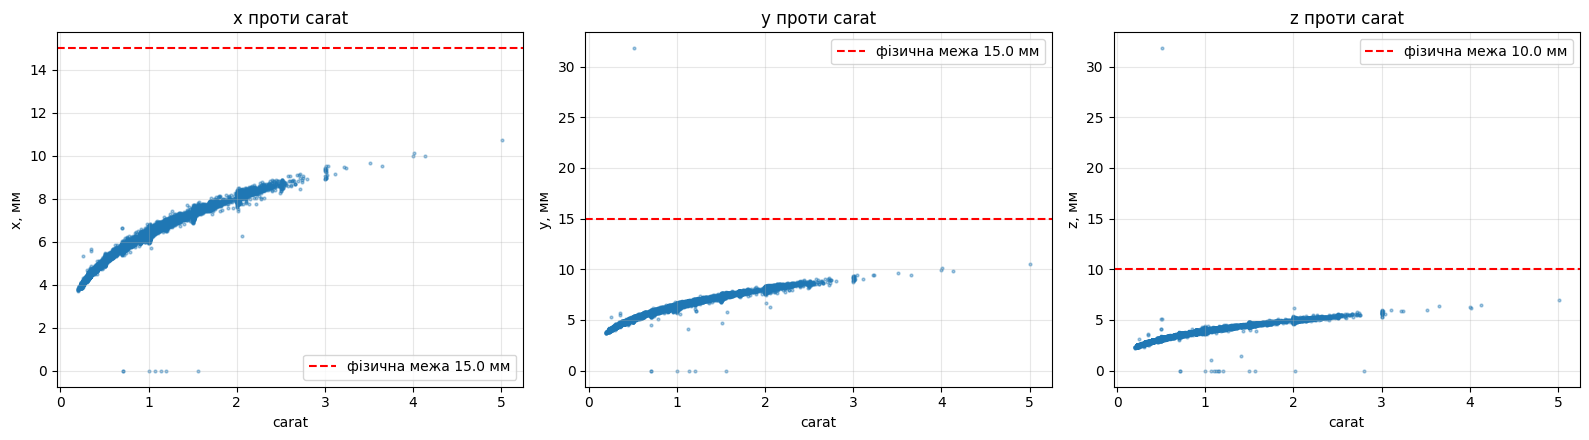

Рядків train із неможливо великими вимірами: 2


,carat,cut,color,clarity,depth,table,price,x,y,z
15904,0.51,Very Good,E,VS1,61.8,54.7,1970,5.12,5.15,31.80
22842,0.51,Ideal,E,VS1,61.8,55.0,2075,5.15,31.80,5.12


In [ ]:
def iqr_outlier_table(df, cols):
    rows = []
    for c in cols:
        q1, q3 = df[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n = int(((df[c] < lo) | (df[c] > hi)).sum())
        rows.append({"колонка": c, "нижня межа": lo, "верхня межа": hi, "викидів": n,
                     "частка, %": 100 * n / len(df), "min": df[c].min(), "max": df[c].max()})
    return pd.DataFrame(rows).set_index("колонка").round(3)


display(iqr_outlier_table(train_df, NUM_COLS))

# Виміри проти ваги: у справжніх каменів x, y, z зростають разом із carat
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, cap in zip(axes, DIM_COLS, [MAX_XY_MM, MAX_XY_MM, MAX_Z_MM]):
    ax.scatter(train_df["carat"], train_df[col], s=4, alpha=0.4)
    ax.axhline(cap, color="r", ls="--", label=f"фізична межа {cap} мм")
    ax.set_xlabel("carat")
    ax.set_ylabel(f"{col}, мм")
    ax.set_title(f"{col} проти carat")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

extreme = train_df[(train_df[["x", "y"]] > MAX_XY_MM).any(axis=1) | (train_df["z"] > MAX_Z_MM)]
print(f"Рядків train із неможливо великими вимірами: {len(extreme)}")
display(extreme)


**Рішення за групами викидів:**

1. **Виміри `x`, `y`, `z`: нулі та екстремально великі значення** (камінь завдовжки в десятки міліметрів при вазі в кілька карат неможливий; вочевидь, це зсув коми або помилка введення, і на графіку такі точки лежать далеко від усієї хмарки й за фізичною межею). Це **помилки даних, а не рідкісні реальні об'єкти**, тому їх не залишаємо. Але й не видаляємо рядки: позначаємо як пропуски й заповнюємо тим самим kNN-імпутером, що й нулі.
2. **`price` і `carat`: довгий правий хвіст.** Це реальні великі й дорогі камені, а не помилки. Видалення «викидів Тьюкі» вирізало б саме той сегмент, де потім доведеться прогнозувати. Тому **залишаємо**; скошеність обробляємо на рівні моделі (окремий експеримент із логарифмом таргета в 2.4).
3. **`depth` і `table`: поодинокі екстремальні пропорції.** Мінімальна й максимальна `table`/`depth` виглядають як рідкісні або неточні виміри. Їх мало, але для лінійної моделі кожна така точка має великий «важіль». Компроміс: **обмежуємо (winsorization)** значення цих двох ознак між 0.1-м і 99.9-м процентилями **train** — межі беремо лише з train, тож витоку немає.

In [ ]:
class Cleaner:
    """Очищення: некоректні виміри -> NaN -> kNN-імпутація; depth/table -> winsorization.
    Усі параметри (масштаб, сусіди, межі) вчимо ТІЛЬКИ на train, до val/test лише застосовуємо."""

    def __init__(self, n_neighbors=5, clip_q=(0.001, 0.999)):
        self.n_neighbors = n_neighbors
        self.clip_q = clip_q

    def _impute(self, marked):
        out = marked.copy()
        z = self.imputer.transform(self.scaler.transform(marked[KNN_COLS]))
        filled = self.scaler.inverse_transform(z)
        for j, col in enumerate(KNN_COLS):
            mask = marked[col].isna().to_numpy()
            if mask.any():
                out.loc[mask, col] = filled[mask, j]  # чіпаємо лише ті клітинки, що були пропусками
        return out

    def fit(self, train):
        marked = mark_invalid_dims(train)
        # kNN працює на відстанях, тож ознаки масштабуємо (NaN StandardScaler ігнорує)
        self.scaler = StandardScaler().fit(marked[KNN_COLS])
        self.imputer = KNNImputer(n_neighbors=self.n_neighbors).fit(self.scaler.transform(marked[KNN_COLS]))
        imputed = self._impute(marked)
        self.clip_bounds = {c: tuple(imputed[c].quantile(list(self.clip_q))) for c in CLIP_COLS}
        return self

    def transform(self, df):
        out = self._impute(mark_invalid_dims(df))
        for col, (lo, hi) in self.clip_bounds.items():
            out[col] = out[col].clip(lo, hi)
        return out


cleaner = Cleaner().fit(train_df)  # навчаємо тільки на train
train_c, val_c, test_c = (cleaner.transform(d) for d in (train_df, val_df, test_df))

report = pd.DataFrame({
    name: mark_invalid_dims(d)[DIM_COLS].isna().sum()
    for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]
}).T
print("Скільки значень x/y/z заповнено kNN-імпутацією:")
display(report)
print("межі winsorization (з train):", {k: tuple(round(v, 2) for v in b) for k, b in cleaner.clip_bounds.items()})
print("NaN після очищення:", int(train_c.isna().sum().sum() + val_c.isna().sum().sum() + test_c.isna().sum().sum()))
print("Мін/макс виміри train після очищення:", train_c[DIM_COLS].min().round(2).to_dict(), train_c[DIM_COLS].max().round(2).to_dict())


Скільки значень x/y/z заповнено kNN-імпутацією:


,x,y,z
train,7,7,14
val,0,1,2
test,1,1,5


межі winsorization (з train): {'depth': (55.8, 68.6), 'table': (52.0, 67.0)}
NaN після очищення: 0
Мін/макс виміри train після очищення: {'x': 3.73, 'y': 3.68, 'z': 1.07} {'x': 10.74, 'y': 10.54, 'z': 6.98}


### 2.1.7. Інженерія ознак

Після очищення дивимось, що кореляції кажуть про ознаки, які можна **прибрати або об'єднати**.

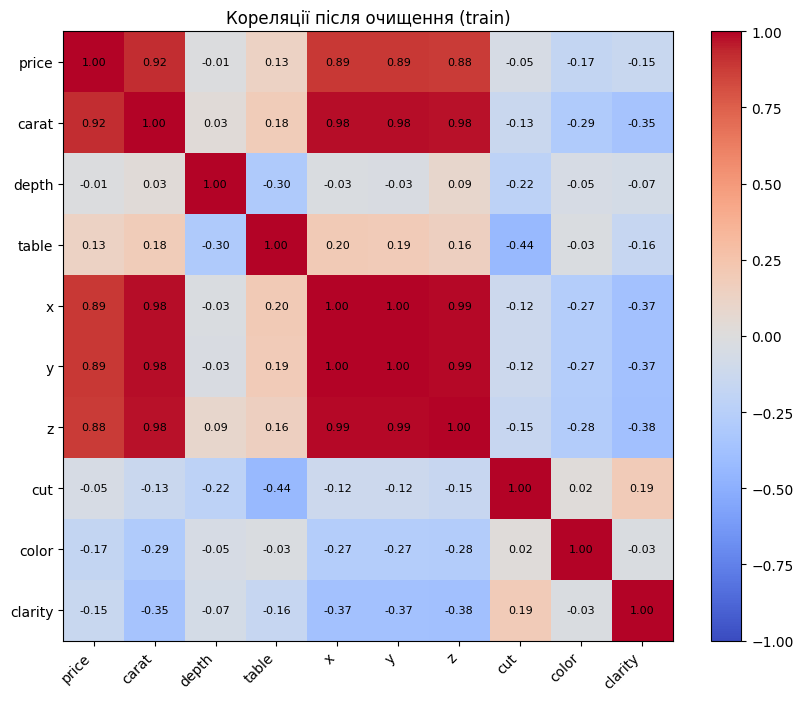

r(carat, x/y/z): {'x': 0.978, 'y': 0.977, 'z': 0.977}
мінімум |r| серед пар x–y, x–z, y–z: 0.991
r(price, ·): {'carat': 0.921, 'x': 0.887, 'y': 0.889, 'z': 0.882}


In [ ]:
enc = encode_ordinals(train_c)
corr_clean = enc[corr_cols].corr()
plot_corr(corr_clean, "Кореляції після очищення (train)")

dims_vs_carat = corr_clean.loc[["x", "y", "z"], "carat"]
dims_vs_dims = corr_clean.loc[["x", "y", "z"], ["x", "y", "z"]].where(~np.eye(3, dtype=bool)).stack()
print("r(carat, x/y/z):", dims_vs_carat.round(3).to_dict())
print("мінімум |r| серед пар x–y, x–z, y–z:", round(float(dims_vs_dims.abs().min()), 3))
print("r(price, ·):", corr_clean.loc["price", ["carat", "x", "y", "z"]].round(3).to_dict())


**Рішення.**

- **Прибираю `x`, `y`, `z`.** Вони майже повністю дублюють `carat` (маса каменя ∝ його об'єм ≈ x·y·z) і є найсильнішими попарними кореляціями в датасеті. Для нейромережі вони майже не несуть нової інформації, а для лінійної моделі створюють мультиколінеарність: ваги цих ознак перерозподіляються між собою й втрачають зміст (див. питання 3). Вони знадобились у 2.1.4–2.1.6, щоб чисто заповнити пропуски, а в модель не йдуть. Зі всіх корельованих ознак лишається `carat`, найсильніше пов'язана з ціною.
- **`cut`, `color`, `clarity` кодую порядковими номерами** (0 — гірше, більше — краще, див. 2.1.1). Шкали природно впорядковані, тож один числовий стовпчик замість 17 one-hot, і модель бачить напрямок «краще → більше». Можливі залежності не лінійні, але це вже завдання нейромережі.
- `depth` і `table` лишаю: це незалежні характеристики огранки, що слабко корелюють із вагою.

Фінальний набір із 6 ознак: `carat`, `cut`, `color`, `clarity`, `depth`, `table`.

In [ ]:
FEATURES = ["carat", "cut", "color", "clarity", "depth", "table"]


def make_features(df, features=None, orderings=None):
    """Сирі колонки -> числова матриця ознак (float32). Використовується і в тренуванні, і в застосунку."""
    features = features or FEATURES
    X = encode_ordinals(df[features], orderings or ORDERINGS)
    if X.isna().any().any():
        raise ValueError("Після кодування категорій з'явились NaN: перевірте значення cut/color/clarity")
    return X.astype("float32")


X_train_df, X_val_df, X_test_df = (make_features(d) for d in (train_c, val_c, test_c))
print("Ознаки:", FEATURES)
print("Форми X:", X_train_df.shape, X_val_df.shape, X_test_df.shape)
X_train_df.head()


Ознаки: ['carat', 'cut', 'color', 'clarity', 'depth', 'table']
Форми X: (37758, 6) (8091, 6) (8091, 6)


,carat,cut,color,clarity,depth,table
0,0.74,4.0,1.0,4.0,61.099998,57.0
1,0.53,4.0,4.0,6.0,61.400002,57.0
2,1.21,2.0,2.0,3.0,62.900002,55.0
3,0.32,4.0,5.0,5.0,61.200001,57.0
4,1.29,4.0,2.0,1.0,61.599998,54.0


## 2.2. Baseline: множинна лінійна регресія

### 2.2.1. Допоміжні засоби

Один набір функцій обслуговує **всі** варіанти моделей (лінійну й нейромережі), тож відрізняються вони лише тим, що ми свідомо змінюємо:

- `Standardizer`, `TargetScaler` — z-нормалізація ознак і таргета (статистики лише з train); `TargetScaler(log=True)` додатково логарифмує ціну;
- `build_mlp(n_in, hidden, activation)` — `nn.Sequential`; порожній `hidden` дає чисту лінійну регресію;
- `train_model` — мініпакетне тренування з логуванням у TensorBoard й відкатом ваг до **найкращої за val епохи**;
- `run_variant` — тренує варіант, оцінює на val, зберігає `models/<ключ>.pt` і реєструє в `VARIANTS`;
- метрики рахуємо в **доларах** (після зворотного перетворення таргета), щоб усі моделі, зокрема з логарифмом, порівнювались чесно.

In [ ]:
class Standardizer:
    """z-нормалізація ознак. mean/std рахуються лише на train."""

    def fit(self, a):
        a = np.asarray(a, dtype=np.float64)
        self.mean = a.mean(axis=0)
        std = a.std(axis=0, ddof=1)
        self.std = np.where(std == 0, 1.0, std)
        return self

    def transform(self, a):
        z = (np.asarray(a, dtype=np.float64) - self.mean) / self.std
        return torch.from_numpy(z.astype(np.float32))


class TargetScaler:
    """Таргет -> z-score. log=True: спершу натуральний логарифм (ціна додатна). inverse() повертає USD."""

    def __init__(self, log=False):
        self.log = log

    def _f(self, y):
        return np.log(y) if self.log else np.asarray(y, dtype=np.float64)

    def fit(self, y):
        z = self._f(y)
        self.mean, self.std = float(z.mean()), float(z.std(ddof=1))
        return self

    def transform(self, y):
        return (self._f(y) - self.mean) / self.std

    def inverse(self, z):
        v = np.asarray(z, dtype=np.float64) * self.std + self.mean
        return np.exp(v) if self.log else v


def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    err = np.asarray(y_pred, dtype=np.float64) - y_true
    mse = float(np.mean(err ** 2))
    ss_tot = float(np.sum((y_true - y_true.mean()) ** 2))
    return {"MSE": mse, "RMSE": math.sqrt(mse), "MAE": float(np.mean(np.abs(err))),
            "R2": 1.0 - float(np.sum(err ** 2)) / ss_tot}


def paired_bootstrap_rmse(y_true, pred_a, pred_b, n_boot=2000, seed=SEED):
    """Парний bootstrap: розподіл різниці RMSE(a) - RMSE(b) на перевибірках одного й того ж test."""
    rng = np.random.default_rng(seed)
    y_true, pred_a, pred_b = (np.asarray(v, dtype=np.float64) for v in (y_true, pred_a, pred_b))
    n = len(y_true)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        diffs[i] = (np.sqrt(np.mean((pred_a[idx] - y_true[idx]) ** 2))
                    - np.sqrt(np.mean((pred_b[idx] - y_true[idx]) ** 2)))
    return float(diffs.mean()), tuple(np.percentile(diffs, [2.5, 97.5]))


ACTIVATIONS = {"relu": nn.ReLU, "tanh": nn.Tanh, "gelu": nn.GELU, "silu": nn.SiLU, "leaky_relu": nn.LeakyReLU}
LOSSES = {"mse": nn.MSELoss, "l1": nn.L1Loss, "huber": nn.HuberLoss}


def build_mlp(n_in, hidden, activation="relu"):
    """n_in -> hidden[0] -> ... -> 1. Порожній hidden = чиста лінійна регресія."""
    layers, prev = [], n_in
    for h in hidden:
        layers += [nn.Linear(prev, h), ACTIVATIONS[activation]()]
        prev = h
    layers.append(nn.Linear(prev, 1))
    return nn.Sequential(*layers)


def make_optimizer(name, params, lr):
    if name == "adam":
        return torch.optim.Adam(params, lr=lr)
    if name == "sgd":
        return torch.optim.SGD(params, lr=lr, momentum=0.9)
    raise ValueError(f"невідомий оптимізатор: {name}")


@torch.no_grad()
def predict_usd(model, X, target_scaler):
    """Прогноз моделі в доларах (зі зворотним перетворенням таргета)."""
    model.eval()
    z = model(X).squeeze(1).numpy().astype(np.float64)
    return target_scaler.inverse(z)


def train_model(run_name, hidden, activation, cfg, target_kind="raw", log_tb=True, seed=SEED):
    """Мініпакетне тренування. Повертає (модель з найкращої за val епохи, історія, інфо)."""
    ts, y_tr, y_va = TARGETS[target_kind]
    set_seed(seed)  # однаковий старт для всіх варіантів -> відрізняються лише заданими змінами
    model = build_mlp(X_tr.shape[1], hidden, activation)
    optimizer = make_optimizer(cfg["optimizer"], model.parameters(), cfg["lr"])
    loss_fn = LOSSES[cfg["loss"]]()
    mse_fn = nn.MSELoss()
    gen = torch.Generator().manual_seed(seed)  # порядок мініпакетів теж відтворюваний

    writer = None
    if log_tb:
        log_dir = os.path.join(RUNS_DIR, run_name)
        shutil.rmtree(log_dir, ignore_errors=True)  # повторний запуск не дублює криві
        writer = SummaryWriter(log_dir=log_dir)

    n, bs = len(X_tr), cfg["batch_size"]
    history, best = [], {"val": float("inf"), "epoch": 0, "state": None}
    t0 = time.time()
    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        perm = torch.randperm(n, generator=gen)
        running = 0.0
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            optimizer.zero_grad()
            loss = loss_fn(model(X_tr[idx]), y_tr[idx])
            loss.backward()
            optimizer.step()
            running += loss.item() * len(idx)
        train_loss = running / n

        model.eval()
        with torch.no_grad():
            pred_va = model(X_va)
            val_loss = loss_fn(pred_va, y_va).item()
            val_mse = mse_fn(pred_va, y_va).item()
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "val_mse": val_mse})
        if writer is not None:
            writer.add_scalar("loss/train", train_loss, epoch)  # однакові теги в усіх прогонів
            writer.add_scalar("loss/val", val_loss, epoch)      # -> криві можна накласти в TensorBoard
        if val_loss < best["val"]:
            best.update(val=val_loss, epoch=epoch, state=copy.deepcopy(model.state_dict()))

    model.load_state_dict(best["state"])  # відкат до найкращої за val епохи
    model.eval()
    if writer is not None:
        writer.flush()
        writer.close()
    info = {"best_epoch": best["epoch"], "best_val_loss": best["val"], "epochs": cfg["epochs"],
            "seconds": time.time() - t0}
    return model, pd.DataFrame(history), info


VARIANTS = {}  # ключ -> усе про натренований варіант


def save_checkpoint(key, v):
    """Самодостатній .pt: ваги + архітектура + статистики нормалізації (для застосунку й відтворення).
    Лише тензори/числа/рядки/списки, тож файл безпечно читати з weights_only=True."""
    ts = TARGETS[v["target"]][0]
    torch.save({
        "state_dict": v["model"].state_dict(),
        "hidden": list(v["hidden"]),
        "activation": v["activation"],
        "features": list(FEATURES),
        "orderings": {k: list(o) for k, o in ORDERINGS.items()},
        "x_mean": x_scaler.mean.tolist(),
        "x_std": x_scaler.std.tolist(),
        "y_mean": float(ts.mean),
        "y_std": float(ts.std),
        "y_log": bool(ts.log),
        "description": v["desc"],
    }, os.path.join(MODELS_DIR, f"{key}.pt"))


def load_variant(path):
    ckpt = torch.load(path, map_location="cpu", weights_only=True)
    model = build_mlp(len(ckpt["features"]), ckpt["hidden"], ckpt["activation"])
    model.load_state_dict(ckpt["state_dict"])
    model.eval()
    return model, ckpt


@torch.no_grad()
def predict_from_ckpt(model, ckpt, raw_df):
    """Сирі колонки (carat, cut, color, clarity, depth, table) -> ціна в USD, лише за вмістом .pt."""
    X = make_features(raw_df, ckpt["features"], ckpt["orderings"]).to_numpy(np.float64)
    a = (X - np.array(ckpt["x_mean"])) / np.array(ckpt["x_std"])
    z = model(torch.tensor(a, dtype=torch.float32)).squeeze(1).numpy().astype(np.float64)
    v = z * ckpt["y_std"] + ckpt["y_mean"]
    return np.exp(v) if ckpt["y_log"] else v


def run_variant(key, run_name, desc, hidden, activation, cfg, target_kind="raw"):
    model, history, info = train_model(run_name, hidden, activation, cfg, target_kind)
    ts = TARGETS[target_kind][0]
    VARIANTS[key] = {
        "model": model, "run": run_name, "desc": desc, "hidden": list(hidden), "activation": activation,
        "cfg": dict(cfg), "target": target_kind, "history": history, "info": info,
        "val": regression_metrics(y_val, predict_usd(model, X_va, ts)), "n_params": count_params(model),
    }
    save_checkpoint(key, VARIANTS[key])
    v = VARIANTS[key]
    print(f"{key:<20} параметрів={v['n_params']:>6} | найкраща епоха {info['best_epoch']:>3}/{cfg['epochs']:<3} | "
          f"val RMSE={v['val']['RMSE']:8.1f} USD | val R²={v['val']['R2']:.4f} | {info['seconds']:.0f} с")
    return v


def variants_table(keys):
    rows = []
    for k in keys:
        v = VARIANTS[k]
        rows.append({"варіант": k, "опис": v["desc"], "параметрів": v["n_params"],
                     "найкраща епоха": v["info"]["best_epoch"], "епох": v["info"]["epochs"],
                     "val RMSE": v["val"]["RMSE"], "val MAE": v["val"]["MAE"], "val R2": v["val"]["R2"]})
    return pd.DataFrame(rows).set_index("варіант").round(4)


def plot_curves(keys, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for k in keys:
        h = VARIANTS[k]["history"]
        axes[0].plot(h["epoch"], h["train_loss"], label=k)
        axes[1].plot(h["epoch"], h["val_loss"], label=k)
    for ax, name in zip(axes, ["train", "val"]):
        ax.set_yscale("log")
        ax.set_xlabel("епоха")
        ax.set_title(f"{name}: функція втрат (на стандартизованому таргеті){' — ' + title if title else ''}")
        ax.grid(alpha=0.3, which="both")
        ax.legend(fontsize=8)
    axes[0].set_ylabel("loss")
    plt.tight_layout()
    plt.show()


### 2.2.2. Стандартизація та тензори

Ознаки стандартизуємо за **train** (`mean`, `std` з train; до val/test лише застосовуємо). Таргет `price` теж стандартизуємо: градієнтному спуску значно легше, коли цільова величина має масштаб ~1, а не тисячі доларів. Прогнози завжди повертаємо в долари перед підрахунком метрик.

In [ ]:
x_scaler = Standardizer().fit(X_train_df.to_numpy())
X_tr, X_va, X_te = (x_scaler.transform(d.to_numpy()) for d in (X_train_df, X_val_df, X_test_df))

y_train, y_val, y_test = (d[TARGET].to_numpy(np.float64) for d in (train_c, val_c, test_c))


def make_targets(log):
    ts = TargetScaler(log=log).fit(y_train)
    as_t = lambda y: torch.from_numpy(ts.transform(y).astype(np.float32)).unsqueeze(1)
    return ts, as_t(y_train), as_t(y_val)


# "raw" -- ціна в доларах (стандартизована); "log" -- стандартизований ln(ціни), використаємо в 2.4
TARGETS = {"raw": make_targets(False), "log": make_targets(True)}

print("X_train:", tuple(X_tr.shape), "| макс |mean| =", round(X_tr.mean(0).abs().max().item(), 6),
      "| середнє std =", round(X_tr.std(0).mean().item(), 4))
print("mean/std ознак (train):", dict(zip(FEATURES, zip(x_scaler.mean.round(2), x_scaler.std.round(2)))))
print("таргет: середнє =", round(TARGETS["raw"][0].mean, 1), "USD, std =", round(TARGETS["raw"][0].std, 1), "USD")


X_train: (37758, 6) | макс |mean| = 0.0 | середнє std = 1.0
mean/std ознак (train): {'carat': (np.float64(0.8), np.float64(0.47)), 'cut': (np.float64(2.9), np.float64(1.12)), 'color': (np.float64(3.4), np.float64(1.7)), 'clarity': (np.float64(3.05), np.float64(1.65)), 'depth': (np.float64(61.75), np.float64(1.41)), 'table': (np.float64(57.46), np.float64(2.22))}
таргет: середнє = 3943.6 USD, std = 3996.3 USD


### 2.2.3. Baseline-середнє (відповідь на питання 4)

Нижня планка: прогноз кожного діаманта **середньою ціною train**. Будь-яка корисна модель повинна бути від неї істотно кращою.

In [ ]:
mean_pred = lambda y: np.full(len(y), y_train.mean())
baseline_val = regression_metrics(y_val, mean_pred(y_val))
baseline_test = regression_metrics(y_test, mean_pred(y_test))
display(pd.DataFrame({"val": baseline_val, "test": baseline_test}).T.round(4))
print("Дисперсія таргета на train:", round(float(y_train.var(ddof=0)), 1), "(= MSE прогнозу середнім на самому train)")


,MSE,RMSE,MAE,R2
val,1.608476e+07,4010.5807,3029.4935,-0.0000
test,1.549014e+07,3935.7516,3005.1505,-0.0004


Дисперсія таргета на train: 15970309.3 (= MSE прогнозу середнім на самому train)


Як і очікувалось, прогноз середнім дає **R² ≈ 0** (на нових даних поруч із нулем), а його MSE дорівнює дисперсії таргета. Усе, що вище, — заслуга ознак.

### 2.2.4. Тренування лінійної регресії та крива навчання

`nn.Linear(6, 1)`, функція втрат MSE, Adam (lr = 0.01), 100 епох, мініпакети по 256. Ваги беруться з епохи з найменшими val-втратами.

linear               параметрів=     7 | найкраща епоха  14/100 | val RMSE=  1248.9 USD | val R²=0.9030 | 9 с


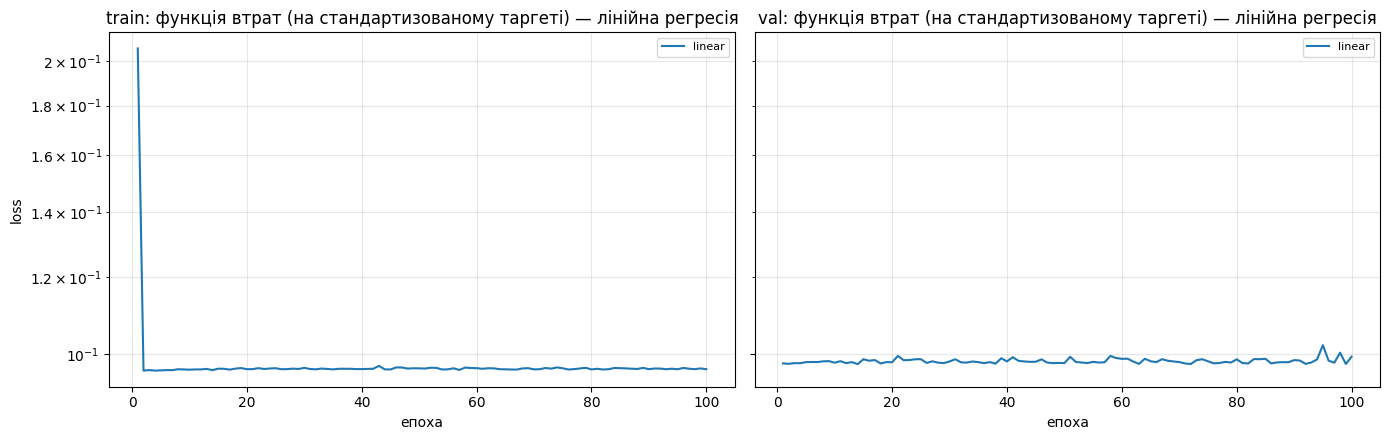

In [ ]:
LINEAR_CFG = dict(optimizer="adam", lr=0.01, epochs=100, batch_size=256, loss="mse")
run_variant("linear", "linear", "Лінійна регресія (nn.Linear, Adam lr=0.01)", hidden=[], activation="relu", cfg=LINEAR_CFG)
plot_curves(["linear"], "лінійна регресія")


### 2.2.5. Перевірка збіжності: градієнтний спуск проти МНК

Для лінійної регресії існує точний розв'язок (метод найменших квадратів). Якщо тренування працює правильно, ваги `nn.Linear` мають збігтися з розв'язком МНК, тож це дешева перевірка всього конвеєра (дані → тензори → оптимізація).

In [ ]:
A = np.c_[X_tr.numpy().astype(np.float64), np.ones(len(X_tr))]
beta, *_ = np.linalg.lstsq(A, TARGETS["raw"][1].numpy().ravel().astype(np.float64), rcond=None)

lin_net = VARIANTS["linear"]["model"][0]
w_nn = lin_net.weight.detach().numpy().ravel()
b_nn = lin_net.bias.item()
print("макс |w_nn − w_МНК| =", float(np.abs(w_nn - beta[:-1]).max()), "| |b_nn − b_МНК| =", abs(b_nn - beta[-1]))

ols_pred = (np.c_[X_te.numpy().astype(np.float64), np.ones(len(X_te))] @ beta) * TARGETS["raw"][0].std + TARGETS["raw"][0].mean
rm_nn = regression_metrics(y_test, predict_usd(VARIANTS["linear"]["model"], X_te, TARGETS["raw"][0]))
rm_ols = regression_metrics(y_test, ols_pred)
display(pd.DataFrame({"nn.Linear (Adam)": rm_nn, "МНК (точний розв'язок)": rm_ols}).T.round(4))


макс |w_nn − w_МНК| = 0.010132960260509742 | |b_nn − b_МНК| = 0.004719829233364774


,MSE,RMSE,MAE,R2
nn.Linear (Adam),1.447770e+06,1203.2332,835.0583,0.9065
МНК (точний розв'язок),1.445710e+06,1202.3768,840.6512,0.9066


### 2.2.6. Метрики на test та інтерпретація ваг (питання 3)

Метрики лінійної моделі на **test** (лише для звіту, test не використовується для будь-яких виборів) і ваги в одиницях стандартних відхилень. Колонка «ефект +1σ» показує, на скільки доларів у середньому змінюється прогноз, якщо ознака зросла на одне стандартне відхилення при незмінних інших.

,MSE,RMSE,MAE,R2
baseline-середнє,1.549014e+07,3935.7516,3005.1505,-0.0004
лінійна регресія,1.447770e+06,1203.2332,835.0583,0.9065


,вага (в σ),"ефект +1σ, USD",r з ціною (сирий)
ознака,,,
carat,1.038,4149.170898,0.921
clarity,0.213,852.455994,-0.147
color,0.138,551.572021,-0.173
cut,0.034,133.994003,-0.051
table,-0.015,-58.855000,0.127
depth,-0.007,-26.014000,-0.013


вільний член (у σ-одиницях таргета): -0.0047


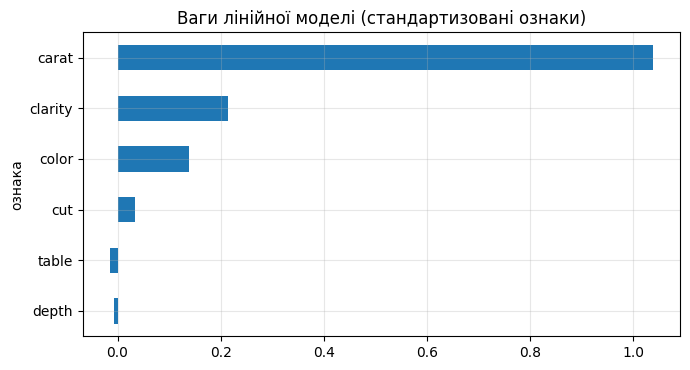

In [ ]:
lin_test = regression_metrics(y_test, predict_usd(VARIANTS["linear"]["model"], X_te, TARGETS["raw"][0]))
display(pd.DataFrame({"baseline-середнє": baseline_test, "лінійна регресія": lin_test}).T.round(4))

y_sd = TARGETS["raw"][0].std
weights_df = pd.DataFrame({
    "ознака": FEATURES,
    "вага (в σ)": w_nn,
    "ефект +1σ, USD": w_nn * y_sd,
    "r з ціною (сирий)": [float(X_train_df[f].corr(train_c[TARGET])) for f in FEATURES],
}).set_index("ознака").sort_values("вага (в σ)", key=np.abs, ascending=False)
display(weights_df.round(3))
print("вільний член (у σ-одиницях таргета):", round(b_nn, 4))

fig, ax = plt.subplots(figsize=(7, 3.8))
weights_df["вага (в σ)"][::-1].plot.barh(ax=ax, color="C0")
ax.set_title("Ваги лінійної моделі (стандартизовані ознаки)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Автоматична інтерпретація ваг: усі твердження випливають з таблиці вище
top = weights_df.index[0]
flip = [f for f in weights_df.index if np.sign(weights_df.loc[f, "r з ціною (сирий)"]) != np.sign(weights_df.loc[f, "вага (в σ)"])]
feat_corr = X_train_df.corr().abs().where(~np.eye(len(FEATURES), dtype=bool)).stack()
pair_max, r_max = feat_corr.idxmax(), feat_corr.max()

lines = ["**Висновки з ваг лінійної моделі:**", ""]
lines.append(f"- **Домінує `{top}`**: +1σ дає {weights_df.loc[top, 'ефект +1σ, USD']:+.0f} USD до прогнозу, "
             f"тобто {abs(weights_df.loc[top, 'вага (в σ)']) / weights_df['вага (в σ)'].abs().sum() * 100:.0f}% сумарного внеску за модулем.")
rest = [f for f in weights_df.index if f != top]
lines.append("- Інші ознаки впливають значно слабше: " + ", ".join(f"`{f}` ({weights_df.loc[f, 'ефект +1σ, USD']:+.0f} USD)" for f in rest) + ".")
QUALITY = ["cut", "color", "clarity"]
flip_q = [f for f in flip if f in QUALITY]
flip_other = [f for f in flip if f not in QUALITY]
if flip_q:
    positive = all(weights_df.loc[f, "вага (в σ)"] > 0 for f in flip_q)
    lines.append("- **Знак ваги протилежний сирій кореляції** для " + ", ".join(f"`{f}`" for f in flip_q)
                 + ": окремо від ваги ця ознака корелює з ціною інакше, ніж діє в моделі. Так проявляється конфаундер: "
                   "«кращі» за кольором/чистотою камені в середньому менші, і лише після врахування `carat` модель відділяє "
                   "їхній власний внесок"
                 + (" (він позитивний: за однакової ваги кращі камені коштують дорожче)." if positive else "."))
for f in flip_other:
    eff, top_eff = weights_df.loc[f, "ефект +1σ, USD"], weights_df.loc[top, "ефект +1σ, USD"]
    tail = ("тож його практичний внесок мінімальний." if abs(eff) < 0.1 * abs(top_eff)
            else "це ефект спільної дії з іншими ознаками.")
    lines.append(f"- `{f}` теж змінює знак відносно сирої кореляції (r = {weights_df.loc[f, 'r з ціною (сирий)']:+.2f} → "
                 f"вага {weights_df.loc[f, 'вага (в σ)']:+.3f}σ), але ефект дуже слабкий ({eff:+.0f} USD на +1σ проти "
                 f"{top_eff:+.0f} USD у `{top}`), {tail}")
if not flip:
    lines.append("- Знаки ваг збігаються зі знаками сирих кореляцій.")
lines.append(f"- Після видалення `x`, `y`, `z` ознаки слабо корельовані: найсильніша пара {pair_max[0]}–{pair_max[1]} має |r| = {r_max:.2f}, "
             "тому ваги можна читати без суттєвого спотворення мультиколінеарністю.")
lines.append(f"- **Межі інтерпретації:** лінійна модель дає R² = {lin_test['R2']:.3f} і RMSE = {lin_test['RMSE']:.0f} USD на test. "
             "Решта дисперсії лишається в похибці; якщо вона має структуру (нелінійність), цю структуру зможе вловити нейромережа (2.3–2.5).")
display(Markdown("\n".join(lines)))


**Висновки з ваг лінійної моделі:**

- **Домінує `carat`**: +1σ дає +4149 USD до прогнозу, тобто 72% сумарного внеску за модулем.
- Інші ознаки впливають значно слабше: `clarity` (+852 USD), `color` (+552 USD), `cut` (+134 USD), `table` (-59 USD), `depth` (-26 USD).
- **Знак ваги протилежний сирій кореляції** для `clarity`, `color`, `cut`: окремо від ваги ця ознака корелює з ціною інакше, ніж діє в моделі. Так проявляється конфаундер: «кращі» за кольором/чистотою камені в середньому менші, і лише після врахування `carat` модель відділяє їхній власний внесок (він позитивний: за однакової ваги кращі камені коштують дорожче).
- `table` теж змінює знак відносно сирої кореляції (r = +0.13 → вага -0.015σ), але ефект дуже слабкий (-59 USD на +1σ проти +4149 USD у `carat`), тож його практичний внесок мінімальний.
- Після видалення `x`, `y`, `z` ознаки слабо корельовані: найсильніша пара cut–table має |r| = 0.44, тому ваги можна читати без суттєвого спотворення мультиколінеарністю.
- **Межі інтерпретації:** лінійна модель дає R² = 0.907 і RMSE = 1203 USD на test. Решта дисперсії лишається в похибці; якщо вона має структуру (нелінійність), цю структуру зможе вловити нейромережа (2.3–2.5).

### 2.2.7. Експеримент до питання 2: вибір функції втрат

Тренуємо **ту саму** лінійну модель з трьома функціями втрат (MSE, MAE/L1, Huber з δ = 1 у σ-одиницях) і порівнюємо їх **за всіма метриками на val** (test не чіпаємо). Це показує, чому одна метрика для тренування й набір метрик для оцінки — різні речі.

In [ ]:
LOSS_NAMES = {"mse": "MSE (L2)", "l1": "MAE (L1)", "huber": "Huber (δ=1)"}
loss_rows = []
for name, label in LOSS_NAMES.items():
    m, h, info = train_model(f"linear_{name}_loss", [], "relu", {**LINEAR_CFG, "loss": name}, "raw", log_tb=False)
    pred = predict_usd(m, X_va, TARGETS["raw"][0])
    loss_rows.append({"функція втрат": label, **regression_metrics(y_val, pred), "найкраща епоха": info["best_epoch"]})
loss_df = pd.DataFrame(loss_rows).set_index("функція втрат")
display(loss_df.round(4))


,MSE,RMSE,MAE,R2,найкраща епоха
функція втрат,,,,,
MSE (L2),1.559744e+06,1248.8970,854.8942,0.9030,14
MAE (L1),1.857417e+06,1362.8710,798.9194,0.8845,14
Huber (δ=1),1.560388e+06,1249.1548,860.1106,0.9030,72


In [ ]:
win = {m: (loss_df[m].idxmax() if m == "R2" else loss_df[m].idxmin()) for m in ["MSE", "RMSE", "MAE", "R2"]}
spread_rmse = (loss_df["RMSE"].max() - loss_df["RMSE"].min()) / loss_df["RMSE"].min() * 100

lines = ["**Результати експерименту (val):**", ""]
lines.append(f"- Найменші MSE / RMSE дає **{win['MSE']}**; найвищий R² — **{win['R2']}**; найменший MAE — **{win['MAE']}**.")
if win["MSE"] == "MSE (L2)" and win["MAE"] == "MAE (L1)":
    lines.append("- Це збігається з теорією: кожна функція втрат найкраще оптимізує «свою» метрику. MSE штрафує великі помилки квадратично "
                 "(тому виграє за MSE/RMSE/R²), а L1 мінімізує саме середню абсолютну помилку.")
else:
    lines.append("- Кожна функція втрат оптимізує «свою» метрику, але на цих даних різниці між ними невеликі й частково потрапляють у межі шуму: "
                 "порядок за різними метриками не повністю збігається з теоретичним.")
lines.append(f"- Розкид RMSE між функціями втрат — {spread_rmse:.1f}%: для лінійної моделі на стандартизованих даних вибір функції втрат "
             "важливий менше, ніж вибір самої моделі (розділи 2.3–2.5).")
lines.append("- Отже, **для тренування обирають диференційовану функцію, узгоджену з бізнес-метрикою (тут MSE), а оцінюють набором метрик**: "
             "RMSE/MAE кажуть, скільки доларів помилки, R² — наскільки краще за середнє.")
display(Markdown("\n".join(lines)))


**Результати експерименту (val):**

- Найменші MSE / RMSE дає **MSE (L2)**; найвищий R² — **MSE (L2)**; найменший MAE — **MAE (L1)**.
- Це збігається з теорією: кожна функція втрат найкраще оптимізує «свою» метрику. MSE штрафує великі помилки квадратично (тому виграє за MSE/RMSE/R²), а L1 мінімізує саме середню абсолютну помилку.
- Розкид RMSE між функціями втрат — 9.1%: для лінійної моделі на стандартизованих даних вибір функції втрат важливий менше, ніж вибір самої моделі (розділи 2.3–2.5).
- Отже, **для тренування обирають диференційовану функцію, узгоджену з бізнес-метрикою (тут MSE), а оцінюють набором метрик**: RMSE/MAE кажуть, скільки доларів помилки, R² — наскільки краще за середнє.

## 2.3. Нейромережа: три різні архітектури

Усі три вирішують ту саму задачу (6 ознак → ціна) з однаковим базовим режимом тренування: **Adam, lr = 0.001, 60 епох, мініпакети по 256, MSE**. Відрізняються вони по суті, а не косметично:

| Ключ | Архітектура | Що перевіряємо |
|---|---|---|
| `nn_v1` | 6 → 64 → 32 → 1, ReLU | опорна неглибока мережа: 2 приховані шари |
| `nn_v2` | 6 → 128 → 64 → 32 → 16 → 1, ReLU | **глибша й ширша**: чи допомагає більша ємність |
| `nn_v3` | 6 → 64 → 32 → 1, **Tanh** | **та сама форма, що v1, інша активація** (насичувана замість ReLU) |

Найкращу архітектуру обираємо за **val**, а test лишається нетронутим до фінального звіту.

In [ ]:
ARCH_SPECS = {
    "nn_v1": dict(run="nn_v1_2layers", hidden=[64, 32], activation="relu", desc="2 приховані шари (64-32), ReLU"),
    "nn_v2": dict(run="nn_v2_deeper", hidden=[128, 64, 32, 16], activation="relu", desc="4 приховані шари (128-64-32-16), ReLU"),
    "nn_v3": dict(run="nn_v3_tanh", hidden=[64, 32], activation="tanh", desc="2 приховані шари (64-32), Tanh"),
}
BASE_CFG = dict(optimizer="adam", lr=1e-3, epochs=60, batch_size=256, loss="mse")

for key, spec in ARCH_SPECS.items():
    run_variant(key, spec["run"], spec["desc"], spec["hidden"], spec["activation"], BASE_CFG)


nn_v1                параметрів=  2561 | найкраща епоха  48/60  | val RMSE=   545.3 USD | val R²=0.9815 | 11 с
nn_v2                параметрів= 11777 | найкраща епоха  59/60  | val RMSE=   545.6 USD | val R²=0.9815 | 20 с
nn_v3                параметрів=  2561 | найкраща епоха  57/60  | val RMSE=   558.6 USD | val R²=0.9806 | 11 с


,опис,параметрів,найкраща епоха,епох,val RMSE,val MAE,val R2
варіант,,,,,,,
linear,"Лінійна регресія (nn.Linear, Adam lr=0.01)",7,14,100,1248.8970,854.8942,0.9030
nn_v1,"2 приховані шари (64-32), ReLU",2561,48,60,545.3010,295.4218,0.9815
nn_v2,"4 приховані шари (128-64-32-16), ReLU",11777,59,60,545.5826,299.7476,0.9815
nn_v3,"2 приховані шари (64-32), Tanh",2561,57,60,558.5552,302.9400,0.9806


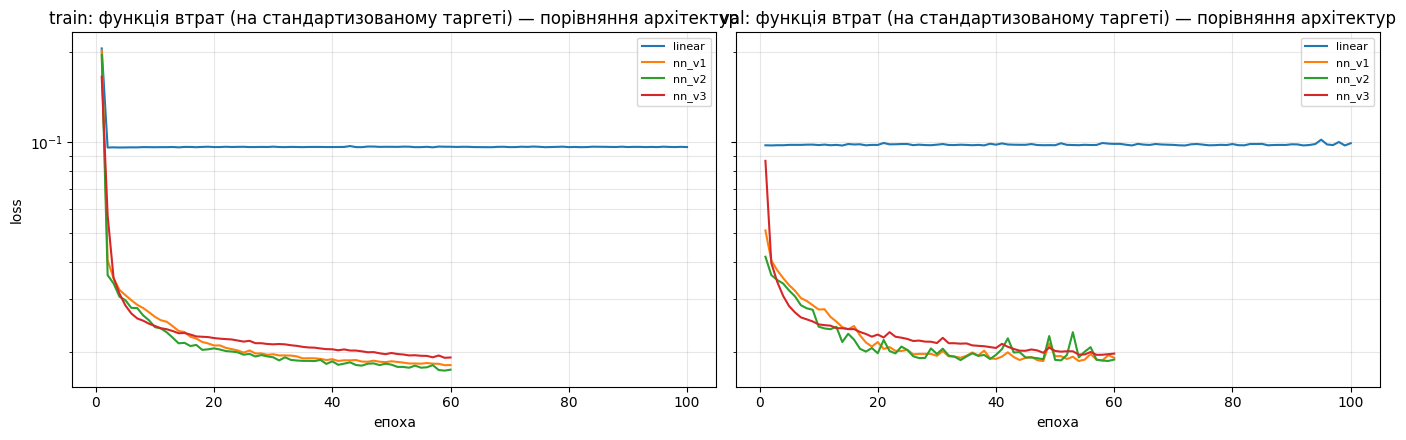

Найкраща архітектура за val RMSE: nn_v1 — 2 приховані шари (64-32), ReLU


In [ ]:
arch_keys = ["linear"] + list(ARCH_SPECS)
display(variants_table(arch_keys))
plot_curves(arch_keys, "порівняння архітектур")

# вибір найкращої архітектури -- за val (НЕ за test)
best_arch = min(ARCH_SPECS, key=lambda k: VARIANTS[k]["val"]["RMSE"])
best_spec = ARCH_SPECS[best_arch]
print(f"Найкраща архітектура за val RMSE: {best_arch} — {best_spec['desc']}")


In [ ]:
# Відповідь на питання 6 на власних мережах: звідки беруться параметри
rows = []
for k in ["linear"] + list(ARCH_SPECS):
    net = VARIANTS[k]["model"]
    layer_sizes = [(m.in_features, m.out_features) for m in net if isinstance(m, nn.Linear)]
    formula = " + ".join(f"({i}·{o}+{o})" for i, o in layer_sizes)
    manual = sum(i * o + o for i, o in layer_sizes)
    assert manual == count_params(net)
    rows.append({"варіант": k, "формула in·out+out по шарах": formula, "разом": manual})
display(pd.DataFrame(rows).set_index("варіант"))


,формула in·out+out по шарах,разом
варіант,,
linear,(6·1+1),7
nn_v1,(6·64+64) + (64·32+32) + (32·1+1),2561
nn_v2,(6·128+128) + (128·64+64) + (64·32+32) + (32·1...,11777
nn_v3,(6·64+64) + (64·32+32) + (32·1+1),2561


Збіг ручного підрахунку за формулою `in·out + out` з `sum(p.numel())` підтверджує пояснення з питання 6: параметри мають лише лінійні шари (активації їх не мають), і їх кількість швидко зростає з шириною шарів (добуток `in·out`).

## 2.4. Підбір гіперпараметрів: по одній зміні за раз

Беремо найкращу за val архітектуру (`best_arch`) з її базовим режимом (`BASE_CFG`) як **точку відліку** і змінюємо **рівно один** параметр, решту лишаючи без змін:

| Ключ-суфікс | Що змінено відносно бази | Навіщо |
|---|---|---|
| `lr_0.01` | learning rate 0.001 → **0.01** | чи не надто повільно йдемо / чи не «перестрибуємо» мінімум |
| `sgd` | оптимізатор Adam → **SGD (momentum 0.9)**, lr той самий | вплив адаптивного оптимізатора |
| `batch_64` | розмір мініпакета 256 → **64** | більш шумні, але частіші оновлення |
| `epochs_150` | кількість епох 60 → **150** | чи вистачало 60 епох (питання 7) |

Окремо в кінці — зміна не гіперпараметра, а **цільової змінної**: навчання на `ln(price)` (скошений таргет, див. EDA) з поверненням у долари.

In [ ]:
HYPER_CHANGES = {
    "lr_0.01": dict(lr=0.01),
    "sgd": dict(optimizer="sgd"),
    "batch_64": dict(batch_size=64),
    "epochs_150": dict(epochs=150),
}

for tag, change in HYPER_CHANGES.items():
    key = f"{best_arch}_{tag}"
    run_variant(key, key, f"{best_spec['desc']}; зміна: {change}", best_spec["hidden"], best_spec["activation"],
                {**BASE_CFG, **change})

# ціль: ln(price) замість price (лише це змінено відносно бази)
logkey = f"{best_arch}_logprice"
_ = run_variant(logkey, logkey, f"{best_spec['desc']}; ціль: ln(price)", best_spec["hidden"], best_spec["activation"],
                BASE_CFG, target_kind="log")


nn_v1_lr_0.01        параметрів=  2561 | найкраща епоха  39/60  | val RMSE=   546.8 USD | val R²=0.9814 | 11 с
nn_v1_sgd            параметрів=  2561 | найкраща епоха  60/60  | val RMSE=   734.5 USD | val R²=0.9665 | 9 с
nn_v1_batch_64       параметрів=  2561 | найкраща епоха  57/60  | val RMSE=   538.7 USD | val R²=0.9820 | 37 с
nn_v1_epochs_150     параметрів=  2561 | найкраща епоха 131/150 | val RMSE=   536.4 USD | val R²=0.9821 | 27 с
nn_v1_logprice       параметрів=  2561 | найкраща епоха  58/60  | val RMSE=   567.8 USD | val R²=0.9800 | 11 с


,опис,параметрів,найкраща епоха,епох,val RMSE,val MAE,val R2
варіант,,,,,,,
nn_v1,"2 приховані шари (64-32), ReLU",2561,48,60,545.3010,295.4218,0.9815
nn_v1_lr_0.01,"2 приховані шари (64-32), ReLU; зміна: {'lr': ...",2561,39,60,546.8480,299.5336,0.9814
nn_v1_sgd,"2 приховані шари (64-32), ReLU; зміна: {'optim...",2561,60,60,734.5306,379.3977,0.9665
nn_v1_batch_64,"2 приховані шари (64-32), ReLU; зміна: {'batch...",2561,57,60,538.6607,290.5357,0.9820
nn_v1_epochs_150,"2 приховані шари (64-32), ReLU; зміна: {'epoch...",2561,131,150,536.3822,289.8396,0.9821
nn_v1_logprice,"2 приховані шари (64-32), ReLU; ціль: ln(price)",2561,58,60,567.7911,298.7165,0.9800


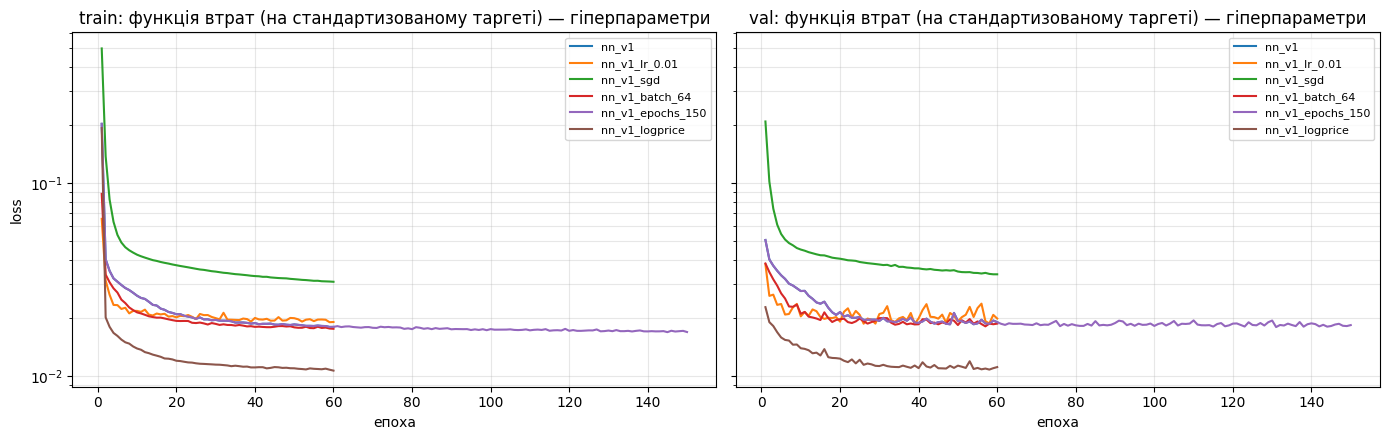

In [ ]:
hyper_keys = [best_arch] + [f"{best_arch}_{t}" for t in HYPER_CHANGES] + [logkey]
display(variants_table(hyper_keys))
plot_curves(hyper_keys, "гіперпараметри")


**Примітка до графіків кривих.** Лінії `nn_v1` на них не видно: її перекриває `nn_v1_epochs_150`. Ці два прогони мають однаковий seed і конфігурацію, тому перші 60 епох їхні криві збігаються, а `epochs_150` просто триває далі. Те саме стосується графіка з усіма варіантами в розділі 2.5.

### Чи відрізняється ефект від випадковості?

Одна зміна гіперпараметра дає одне число, але навіть без змін мережа при іншому `seed` дає трохи інший результат. Щоб відрізнити справжній ефект від шуму, перетренуємо базову конфігурацію з **трьома іншими seed** і подивимось на розкид val RMSE (на val, щоб не чіпати test).

In [ ]:
ts_raw = TARGETS["raw"][0]
seed_rmse = [VARIANTS[best_arch]["val"]["RMSE"]]
for s in [SEED + 1, SEED + 2, SEED + 3]:
    m, h, info = train_model("seed_check", best_spec["hidden"], best_spec["activation"], BASE_CFG, "raw", log_tb=False, seed=s)
    seed_rmse.append(regression_metrics(y_val, predict_usd(m, X_va, ts_raw))["RMSE"])
seed_noise = float(np.std(seed_rmse, ddof=1))
print("val RMSE при різних seed:", [round(v, 1) for v in seed_rmse], "| std =", round(seed_noise, 1), "USD")

# Таблиця ефектів змін відносно бази (за val)
base_val_rmse = VARIANTS[best_arch]["val"]["RMSE"]
eff_rows = []
for k in hyper_keys[1:]:
    d = VARIANTS[k]["val"]["RMSE"] - base_val_rmse
    verdict = "у межах шуму seed" if abs(d) < 2 * seed_noise else ("краще" if d < 0 else "гірше")
    eff_rows.append({"варіант": k, "val RMSE": VARIANTS[k]["val"]["RMSE"], "Δ vs база, USD": d,
                     "Δ, %": 100 * d / base_val_rmse, "висновок": verdict})
effects_df = pd.DataFrame(eff_rows).set_index("варіант")
display(effects_df.round(2))


val RMSE при різних seed: [545.3, 559.7, 550.1, 549.1] | std = 6.1 USD


,val RMSE,"Δ vs база, USD","Δ, %",висновок
варіант,,,,
nn_v1_lr_0.01,546.85,1.55,0.28,у межах шуму seed
nn_v1_sgd,734.53,189.23,34.70,гірше
nn_v1_batch_64,538.66,-6.64,-1.22,у межах шуму seed
nn_v1_epochs_150,536.38,-8.92,-1.64,у межах шуму seed
nn_v1_logprice,567.79,22.49,4.12,гірше


In [ ]:
# Питання 7: чи вистачало епох? Положення мінімуму val відносно кінця тренування
ep_rows = []
for k, v in VARIANTS.items():
    be, tot = v["info"]["best_epoch"], v["info"]["epochs"]
    status = ("мінімум наприкінці: можливо, епох замало" if be >= 0.9 * tot
              else "мінімум рано: плато/перенавчання, решта епох зайва" if be <= 0.5 * tot
              else "мінімум у середині-кінці: епох достатньо")
    ep_rows.append({"варіант": k, "найкраща епоха": be, "усього епох": tot, "частка": round(be / tot, 2), "висновок": status})
display(pd.DataFrame(ep_rows).set_index("варіант"))


,найкраща епоха,усього епох,частка,висновок
варіант,,,,
linear,14,100,0.14,"мінімум рано: плато/перенавчання, решта епох з..."
nn_v1,48,60,0.80,мінімум у середині-кінці: епох достатньо
nn_v2,59,60,0.98,"мінімум наприкінці: можливо, епох замало"
nn_v3,57,60,0.95,"мінімум наприкінці: можливо, епох замало"
nn_v1_lr_0.01,39,60,0.65,мінімум у середині-кінці: епох достатньо
nn_v1_sgd,60,60,1.00,"мінімум наприкінці: можливо, епох замало"
nn_v1_batch_64,57,60,0.95,"мінімум наприкінці: можливо, епох замало"
nn_v1_epochs_150,131,150,0.87,мінімум у середині-кінці: епох достатньо
nn_v1_logprice,58,60,0.97,"мінімум наприкінці: можливо, епох замало"


## 2.5. Логування (TensorBoard) і порівняння всіх варіантів

Кожен варіант записував криві `loss/train` і `loss/val` у власну підпапку `runs/<назва>`. Однакові теги й різні папки дозволяють TensorBoard накласти всі прогони на один графік.

На цьому етапі вперше рахуємо метрики на **test**: для всіх варіантів, один раз, без жодного впливу на вибір моделей.

In [ ]:
%load_ext tensorboard
%tensorboard --logdir {RUNS_DIR}


<IPython.core.display.Javascript object>

In [ ]:
TEST_PRED, rows = {}, []
for key, v in VARIANTS.items():
    TEST_PRED[key] = predict_usd(v["model"], X_te, TARGETS[v["target"]][0])
    rows.append({"model": key, **regression_metrics(y_test, TEST_PRED[key])})

results_df = pd.DataFrame(rows)
results_df.round(4).to_csv(RESULTS_CSV, index=False)  # model, MSE, RMSE, MAE, R2 (test)
print("Збережено:", RESULTS_CSV)

shown = results_df.merge(
    pd.DataFrame({"model": list(VARIANTS), "параметрів": [v["n_params"] for v in VARIANTS.values()],
                  "опис": [v["desc"] for v in VARIANTS.values()]}), on="model").set_index("model")
display(shown.sort_values("RMSE").round(4))
print("Baseline-середнє (test): RMSE =", round(baseline_test["RMSE"], 1), "USD, R² =", round(baseline_test["R2"], 4))


Збережено: /content/drive/MyDrive/ai_systems/lab2/results.csv


,MSE,RMSE,MAE,R2,параметрів,опис
model,,,,,,
nn_v1_epochs_150,2.808516e+05,529.9544,283.2027,0.9819,2561,"2 приховані шари (64-32), ReLU; зміна: {'epoch..."
nn_v1_batch_64,2.867254e+05,535.4675,285.6606,0.9815,2561,"2 приховані шари (64-32), ReLU; зміна: {'batch..."
nn_v1,2.898888e+05,538.4132,288.3839,0.9813,2561,"2 приховані шари (64-32), ReLU"
nn_v2,2.915217e+05,539.9275,294.3450,0.9812,11777,"4 приховані шари (128-64-32-16), ReLU"
nn_v1_lr_0.01,2.946403e+05,542.8078,295.4665,0.9810,2561,"2 приховані шари (64-32), ReLU; зміна: {'lr': ..."
nn_v3,3.012183e+05,548.8336,297.3966,0.9805,2561,"2 приховані шари (64-32), Tanh"
nn_v1_logprice,3.078237e+05,554.8186,291.0003,0.9801,2561,"2 приховані шари (64-32), ReLU; ціль: ln(price)"
nn_v1_sgd,4.516209e+05,672.0275,365.3772,0.9708,2561,"2 приховані шари (64-32), ReLU; зміна: {'optim..."
linear,1.447770e+06,1203.2332,835.0583,0.9065,7,"Лінійна регресія (nn.Linear, Adam lr=0.01)"


Baseline-середнє (test): RMSE = 3935.8 USD, R² = -0.0004


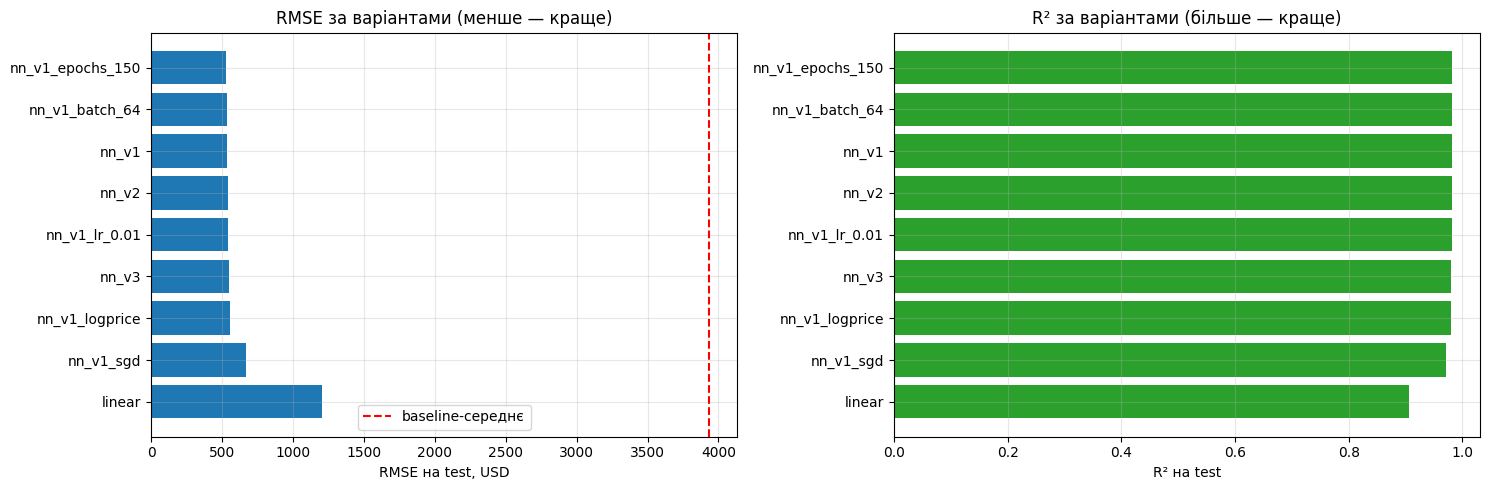

In [ ]:
order = results_df.sort_values("RMSE", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh(order["model"], order["RMSE"], color="C0")
axes[0].axvline(baseline_test["RMSE"], color="r", ls="--", label="baseline-середнє")
axes[0].set_xlabel("RMSE на test, USD")
axes[0].set_title("RMSE за варіантами (менше — краще)")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].barh(order["model"], order["R2"], color="C2")
axes[1].set_xlabel("R² на test")
axes[1].set_title("R² за варіантами (більше — краще)")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()


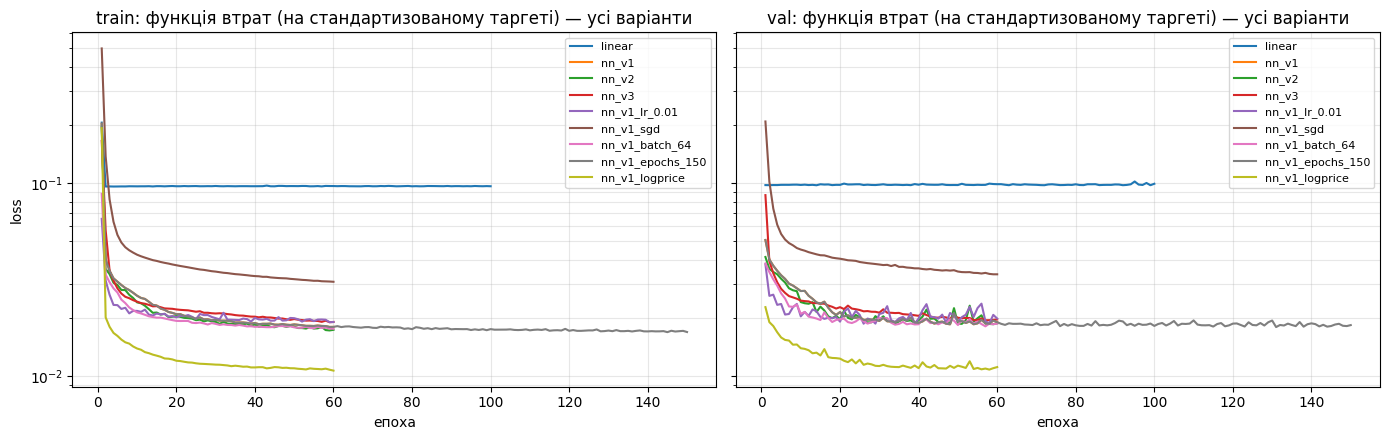

In [ ]:
# Накладання кривих val усіх варіантів (те саме, що покаже TensorBoard)
plot_curves(list(VARIANTS), "усі варіанти")


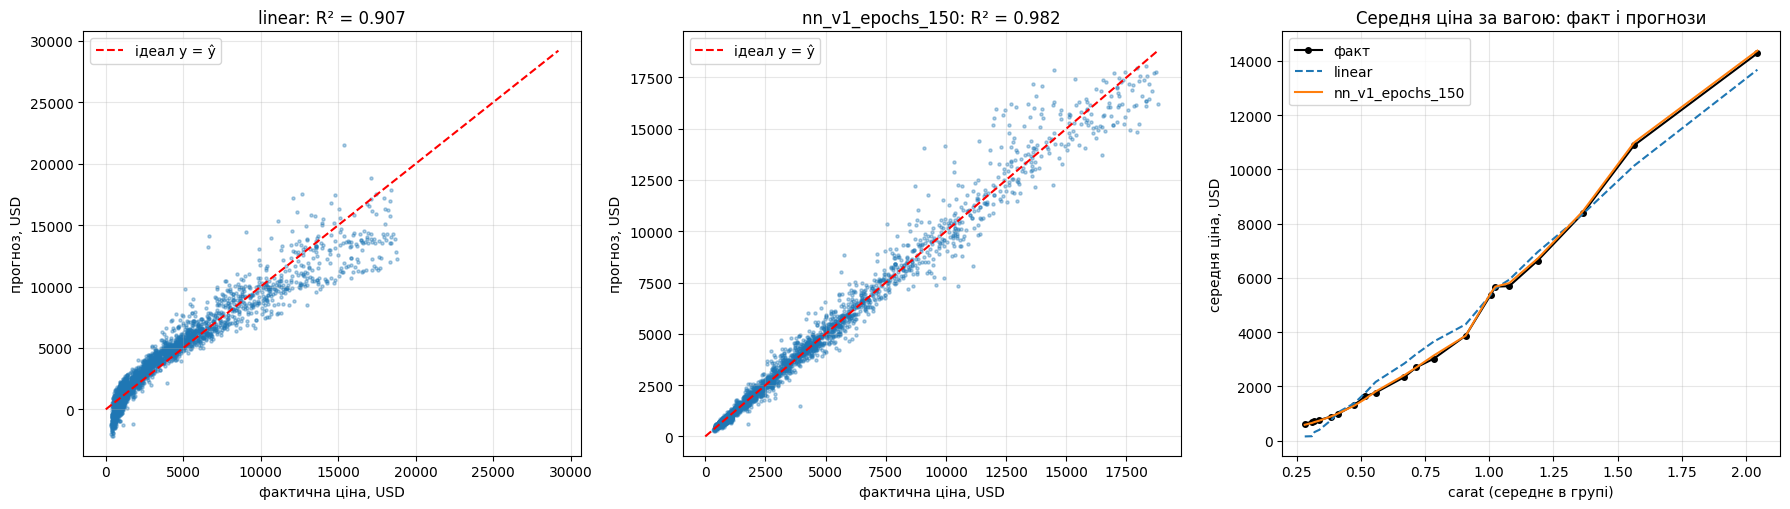

In [ ]:
res = results_df.set_index("model")
best_key = res["RMSE"].idxmin()
best_nn_key = res.drop(index="linear")["RMSE"].idxmin()

# Візуальна діагностика: «факт проти прогноз» та середні прогнози за вагою каменя
sample = np.random.default_rng(SEED).choice(len(y_test), size=min(3000, len(y_test)), replace=False)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for ax, key in zip(axes[:2], ["linear", best_nn_key]):
    ax.scatter(y_test[sample], TEST_PRED[key][sample], s=5, alpha=0.35)
    lim = [0, max(y_test.max(), TEST_PRED[key].max())]
    ax.plot(lim, lim, "r--", label="ідеал y = ŷ")
    ax.set_xlabel("фактична ціна, USD")
    ax.set_ylabel("прогноз, USD")
    ax.set_title(f"{key}: R² = {res.loc[key, 'R2']:.3f}")
    ax.legend()
    ax.grid(alpha=0.3)

bins = pd.qcut(test_c["carat"], 20, duplicates="drop")
by_carat = pd.DataFrame({"carat": test_c["carat"].to_numpy(), "факт": y_test, "linear": TEST_PRED["linear"],
                         best_nn_key: TEST_PRED[best_nn_key]}).groupby(bins.cat.codes.to_numpy()).mean()
for col, style in [("факт", "k-o"), ("linear", "C0--"), (best_nn_key, "C1-")]:
    axes[2].plot(by_carat["carat"], by_carat[col], style, label=col, ms=4)
axes[2].set_xlabel("carat (середнє в групі)")
axes[2].set_ylabel("середня ціна, USD")
axes[2].set_title("Середня ціна за вагою: факт і прогнози")
axes[2].legend()
axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Відповіді на запитання про результати: усі твердження й числа беруться з таблиць вище
lin = res.loc["linear"]
bn = res.loc[best_nn_key]
pct = lambda a, b: 100 * (a - b) / a
mean_diff, (ci_lo, ci_hi) = paired_bootstrap_rmse(y_test, TEST_PRED["linear"], TEST_PRED[best_nn_key])
gain_rmse, gain_mae = pct(lin["RMSE"], bn["RMSE"]), pct(lin["MAE"], bn["MAE"])
significant = ci_lo > 0

lines = ["### Відповіді за результатами (test)", ""]
lines.append("**1. Яка модель перемогла і наскільки суттєво?**")
lines.append("")
if best_key == "linear":
    lines.append(f"Найкращою за RMSE виявилась **лінійна регресія** (RMSE = {lin['RMSE']:.1f} USD, R² = {lin['R2']:.4f}): жодна з нейромереж її не перевершила. "
                 f"Найкраща нейромережа — `{best_nn_key}` (RMSE = {bn['RMSE']:.1f} USD).")
else:
    lines.append(f"За RMSE на test перемогла `{best_key}` ({VARIANTS[best_key]['desc']}): RMSE = **{res.loc[best_key, 'RMSE']:.1f} USD**, "
                 f"MAE = {res.loc[best_key, 'MAE']:.1f} USD, R² = **{res.loc[best_key, 'R2']:.4f}**. "
                 f"Для порівняння: лінійна регресія має RMSE = {lin['RMSE']:.1f} USD, MAE = {lin['MAE']:.1f} USD, R² = {lin['R2']:.4f}; "
                 f"baseline-середнє — RMSE = {baseline_test['RMSE']:.1f} USD, R² = {baseline_test['R2']:.4f}.")
lines.append("")
lines.append(f"Найкраща нейромережа проти лінійної (`{best_nn_key}`): RMSE менше на **{gain_rmse:.1f}%**, MAE — на **{gain_mae:.1f}%**, "
             f"R² вище на {100 * (bn['R2'] - lin['R2']):.1f} в.п. Парний bootstrap (2000 перевибірок test) дає 95% довірчий інтервал для різниці RMSE "
             f"(лінійна − нейромережа): [{ci_lo:.1f}; {ci_hi:.1f}] USD — "
             + ("інтервал не містить нуля, тож перевага **статистично значуща**." if significant
                else "інтервал містить нуль, тож перевагу не можна вважати статистично підтвердженою."))
close = [k for k in res.index if k not in ("linear", best_nn_key) and res.loc[k, "RMSE"] - bn["RMSE"] <= 2 * seed_noise]
if close:
    lines.append("")
    lines.append(f"Але перемога `{best_nn_key}` над найближчими суперниками — "
                 + ", ".join(f"`{k}` (+{res.loc[k, 'RMSE'] - bn['RMSE']:.1f} USD)" for k in close)
                 + f" — менша за подвоєний шум між seed (≈ {2 * seed_noise:.1f} USD, розділ 2.4): за іншого seed порядок у цій групі міг би змінитися. "
                   "Надійно відрізняються від переможця лише варіанти, які відстають більше, ніж на цей поріг.")
lines.append("")
lines.append("**2. Чи виправдала себе нейромережа порівняно з лінійною регресією?**")
lines.append("")
cost = f"Ціна цього: {VARIANTS[best_nn_key]['n_params']} параметрів проти {VARIANTS['linear']['n_params']} і {VARIANTS[best_nn_key]['info']['seconds']:.0f} с тренування проти {VARIANTS['linear']['info']['seconds']:.0f} с."
if gain_rmse >= 10 and significant:
    lines.append(f"**Так, виправдала.** Зменшення RMSE на {gain_rmse:.0f}% суттєве й статистично значуще. {cost} "
                 "Діагностика на графіках вище допомагає зрозуміти причину: лінійна модель може лише «провести пряму» через залежність ціни від ваги, "
                 "тоді як справжня залежність вигнута (права панель діагностики) і, найімовірніше, залежить від взаємодії ваги з чистотою та кольором; мережа з нелінійними активаціями здатна це вловити.")
elif gain_rmse > 0 and significant:
    lines.append(f"**Частково.** Перевага нейромережі є й статистично значуща, але помірна ({gain_rmse:.1f}%). {cost} "
                 "Чи варта така економія помилки додаткової складності й гіршої інтерпретованості — залежить від вимог до точності.")
else:
    lines.append(f"**Ні, на цих даних і з цими налаштуваннями — не виправдала.** Виграш ({gain_rmse:.1f}% за RMSE) або відсутній, або в межах статистичної невизначеності. {cost} "
                 "Тут простіша й інтерпретовна лінійна модель — розумніший вибір.")
lines.append("")
lines.append("**3. Що з змін (архітектура чи гіперпараметри) дало найбільший ефект?**")
lines.append("")
arch_rmse = {k: res.loc[k, "RMSE"] for k in ARCH_SPECS}
arch_spread = max(arch_rmse.values()) - min(arch_rmse.values())
lines.append("Архітектури (test RMSE): " + "; ".join(f"`{k}` — {v:.1f} USD" for k, v in arch_rmse.items())
             + f". Найкраща за val — `{best_arch}`; розкид між архітектурами — {arch_spread:.1f} USD "
             f"({100 * arch_spread / min(arch_rmse.values()):.1f}%). Для порівняння: перехід від лінійної моделі до найгіршої з цих нейромереж "
             f"{'зменшує' if lin['RMSE'] >= max(arch_rmse.values()) else 'збільшує'} RMSE на {abs(pct(lin['RMSE'], max(arch_rmse.values()))):.1f}%.")
lines.append("")
lines.append(f"Зміни відносно бази `{best_arch}` (за val; шум між seed ≈ {seed_noise:.1f} USD, тож зміни менші за ≈ {2 * seed_noise:.1f} USD вважаємо шумом):")
lines.append("")
for k, r in effects_df.iterrows():
    tag = k.replace(f"{best_arch}_", "")
    lines.append(f"- `{tag}`: Δ val RMSE = {r['Δ vs база, USD']:+.1f} USD ({r['Δ, %']:+.1f}%) — {r['висновок']}; test RMSE = {res.loc[k, 'RMSE']:.1f} USD.")
biggest = effects_df["Δ vs база, USD"].abs().idxmax()
lines.append("")
lines.append(f"**Найбільший ефект серед змін дала `{biggest.replace(best_arch + '_', '')}`** "
             f"(Δ = {effects_df.loc[biggest, 'Δ vs база, USD']:+.1f} USD на val, {effects_df.loc[biggest, 'висновок']}). "
             "Зміни, позначені «у межах шуму seed», не дають підстав стверджувати, що вони щось покращили.")
display(Markdown("\n".join(lines)))


### Відповіді за результатами (test)

**1. Яка модель перемогла і наскільки суттєво?**

За RMSE на test перемогла `nn_v1_epochs_150` (2 приховані шари (64-32), ReLU; зміна: {'epochs': 150}): RMSE = **530.0 USD**, MAE = 283.2 USD, R² = **0.9819**. Для порівняння: лінійна регресія має RMSE = 1203.2 USD, MAE = 835.1 USD, R² = 0.9065; baseline-середнє — RMSE = 3935.8 USD, R² = -0.0004.

Найкраща нейромережа проти лінійної (`nn_v1_epochs_150`): RMSE менше на **56.0%**, MAE — на **66.1%**, R² вище на 7.5 в.п. Парний bootstrap (2000 перевибірок test) дає 95% довірчий інтервал для різниці RMSE (лінійна − нейромережа): [629.6; 716.9] USD — інтервал не містить нуля, тож перевага **статистично значуща**.

Але перемога `nn_v1_epochs_150` над найближчими суперниками — `nn_v1_batch_64` (+5.5 USD), `nn_v1` (+8.5 USD), `nn_v2` (+10.0 USD) — менша за подвоєний шум між seed (≈ 12.3 USD, розділ 2.4): за іншого seed порядок у цій групі міг би змінитися. Надійно відрізняються від переможця лише варіанти, які відстають більше, ніж на цей поріг.

**2. Чи виправдала себе нейромережа порівняно з лінійною регресією?**

**Так, виправдала.** Зменшення RMSE на 56% суттєве й статистично значуще. Ціна цього: 2561 параметрів проти 7 і 27 с тренування проти 9 с. Діагностика на графіках вище допомагає зрозуміти причину: лінійна модель може лише «провести пряму» через залежність ціни від ваги, тоді як справжня залежність вигнута (права панель діагностики) і, найімовірніше, залежить від взаємодії ваги з чистотою та кольором; мережа з нелінійними активаціями здатна це вловити.

**3. Що з змін (архітектура чи гіперпараметри) дало найбільший ефект?**

Архітектури (test RMSE): `nn_v1` — 538.4 USD; `nn_v2` — 539.9 USD; `nn_v3` — 548.8 USD. Найкраща за val — `nn_v1`; розкид між архітектурами — 10.4 USD (1.9%). Для порівняння: перехід від лінійної моделі до найгіршої з цих нейромереж зменшує RMSE на 54.4%.

Зміни відносно бази `nn_v1` (за val; шум між seed ≈ 6.1 USD, тож зміни менші за ≈ 12.3 USD вважаємо шумом):

- `lr_0.01`: Δ val RMSE = +1.5 USD (+0.3%) — у межах шуму seed; test RMSE = 542.8 USD.
- `sgd`: Δ val RMSE = +189.2 USD (+34.7%) — гірше; test RMSE = 672.0 USD.
- `batch_64`: Δ val RMSE = -6.6 USD (-1.2%) — у межах шуму seed; test RMSE = 535.5 USD.
- `epochs_150`: Δ val RMSE = -8.9 USD (-1.6%) — у межах шуму seed; test RMSE = 530.0 USD.
- `logprice`: Δ val RMSE = +22.5 USD (+4.1%) — гірше; test RMSE = 554.8 USD.

**Найбільший ефект серед змін дала `sgd`** (Δ = +189.2 USD на val, гірше). Зміни, позначені «у межах шуму seed», не дають підстав стверджувати, що вони щось покращили.

### Перевірка збережених артефактів

Файли `models/*.pt` мають бути **самодостатніми**: за ними (без об'єктів із пам'яті ноутбука) повинні відтворюватись ті самі прогнози. Це саме те, що потім робить Gradio-застосунок. Завантажуємо кожен файл, прогнозуємо test з **сирих** колонок і порівнюємо з прогнозами, які були в пам'яті.

In [ ]:
check_rows = []
for key in VARIANTS:
    model_f, ckpt_f = load_variant(os.path.join(MODELS_DIR, f"{key}.pt"))
    pred_f = predict_from_ckpt(model_f, ckpt_f, test_c)
    max_diff = float(np.abs(pred_f - TEST_PRED[key]).max())
    check_rows.append({"модель": key, "макс. |Δ прогнозу|, USD": max_diff, "збігається": max_diff < 0.05})
display(pd.DataFrame(check_rows).set_index("модель").round(6))

print("models/:", sorted(os.listdir(MODELS_DIR)))
print("runs/  :", sorted(os.listdir(RUNS_DIR)))
print("results.csv існує:", os.path.exists(RESULTS_CSV))


,"макс. |Δ прогнозу|, USD",збігається
модель,,
linear,0.0,True
nn_v1,0.0,True
nn_v2,0.0,True
nn_v3,0.0,True
nn_v1_lr_0.01,0.0,True
nn_v1_sgd,0.0,True
nn_v1_batch_64,0.0,True
nn_v1_epochs_150,0.0,True
nn_v1_logprice,0.0,True


models/: ['linear.pt', 'nn_v1.pt', 'nn_v1_batch_64.pt', 'nn_v1_epochs_150.pt', 'nn_v1_logprice.pt', 'nn_v1_lr_0.01.pt', 'nn_v1_sgd.pt', 'nn_v2.pt', 'nn_v3.pt']
runs/  : ['linear', 'nn_v1_2layers', 'nn_v1_batch_64', 'nn_v1_epochs_150', 'nn_v1_logprice', 'nn_v1_lr_0.01', 'nn_v1_sgd', 'nn_v2_deeper', 'nn_v3_tanh']
results.csv існує: True


---
## 3. Gradio-застосунок: порівняння всіх варіантів наживо

Побудуйте аппку для своїх моделей

Застосунок **читає лише збережені файли** (`models/*.pt` та `results.csv`) і не користується об'єктами з пам'яті ноутбука: тим самим він перевіряє, що артефакти справді самодостатні. Що він вміє:

- **«Власні значення»** — задаєте характеристики діаманта, а застосунок показує прогнози **всіх** варіантів поруч (таблиця й діаграма), впорядковані від найточнішої моделі на test;
- **«Випадковий діамант із test»** — бере реальний камінь, якого моделі не бачили під час тренування, показує його справжню ціну й помилку кожної моделі;
- **«Результати на test»** — підсумкова таблиця метрик усіх варіантів.

In [ ]:
try:
    import gradio as gr
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gradio"])
    import gradio as gr
from matplotlib.figure import Figure

# усі моделі беремо з диска -- саме ці файли здаються як результат
APP_MODELS = {}
for fname in sorted(os.listdir(MODELS_DIR)):
    if fname.endswith(".pt"):
        APP_MODELS[fname[:-3]] = load_variant(os.path.join(MODELS_DIR, fname))
app_results = pd.read_csv(RESULTS_CSV).set_index("model")
print("Завантажено моделей:", list(APP_MODELS))


def predict_all(raw_df):
    """Прогнози всіх моделей для одного рядка (сирі колонки), від найточнішої на test."""
    rows = []
    for key, (model, ckpt) in APP_MODELS.items():
        rows.append({
            "Модель": key,
            "Прогноз, USD": round(float(predict_from_ckpt(model, ckpt, raw_df)[0]), 0),
            "RMSE на test, USD": round(float(app_results.loc[key, "RMSE"]), 0) if key in app_results.index else float("nan"),
            "R² на test": round(float(app_results.loc[key, "R2"]), 4) if key in app_results.index else float("nan"),
        })
    return pd.DataFrame(rows).sort_values("RMSE на test, USD").reset_index(drop=True)


def make_plot(table, truth=None):
    fig = Figure(figsize=(7, 0.45 * len(table) + 1.8))  # Figure без pyplot: не накопичує фігур між запитами
    ax = fig.subplots()
    ax.barh(table["Модель"].tolist()[::-1], table["Прогноз, USD"].tolist()[::-1], color="C0")
    if truth is not None:
        ax.axvline(truth, color="r", ls="--", label=f"фактична ціна: {truth:,.0f} USD")
        ax.legend()
    ax.set_xlabel("прогноз ціни, USD")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    return fig


def predict_custom(carat, cut, color, clarity, depth, table):
    raw = pd.DataFrame([{"carat": carat, "cut": cut, "color": color, "clarity": clarity, "depth": depth, "table": table}])
    t = predict_all(raw)
    return t, make_plot(t)


def predict_random():
    row = test_c.iloc[[int(np.random.randint(len(test_c)))]]
    truth = float(row[TARGET].iloc[0])
    t = predict_all(row)
    t["Похибка, USD"] = (t["Прогноз, USD"] - truth).round(0)
    d = row.iloc[0]
    info = (f"**Діамант із test:** {d['carat']:.2f} кт, огранка {d['cut']}, колір {d['color']}, чистота {d['clarity']}, "
            f"depth {d['depth']:.1f}%, table {d['table']:.1f}%.  \n**Фактична ціна: {truth:,.0f} USD**")
    return info, t, make_plot(t, truth)


with gr.Blocks(title="Diamonds: порівняння моделей") as demo:
    gr.Markdown("# Ціна діаманта: порівняння всіх варіантів моделей\n"
                "Лінійна регресія та нейромережі з лабораторної роботи 2. Моделі завантажені з файлів `models/*.pt`.")
    with gr.Tab("Власні значення"):
        with gr.Row():
            with gr.Column():
                carat_in = gr.Slider(0.2, 5.0, value=0.7, step=0.01, label="carat — вага, карат")
                cut_in = gr.Dropdown(CUT_ORDER[::-1], value="Ideal", label="cut — огранка (Ideal — найкраща)")
                color_in = gr.Dropdown(COLOR_ORDER[::-1], value="G", label="color — колір (D — безбарвний, J — найгірший)")
                clarity_in = gr.Dropdown(CLARITY_ORDER[::-1], value="VS2", label="clarity — чистота (IF — найкраща)")
                depth_in = gr.Slider(43, 79, value=61.8, step=0.1, label="depth — загальна висота, % від діаметра")
                table_in = gr.Slider(43, 95, value=57, step=0.5, label="table — ширина верхньої площини, %")
                btn = gr.Button("Порахувати прогнози", variant="primary")
            with gr.Column():
                out_table = gr.Dataframe(label="Прогнози всіх моделей (від найточнішої на test)", interactive=False)
                out_plot = gr.Plot(label="Порівняння прогнозів")
        btn.click(predict_custom, inputs=[carat_in, cut_in, color_in, clarity_in, depth_in, table_in],
                  outputs=[out_table, out_plot])
    with gr.Tab("Випадковий діамант із test"):
        rnd_btn = gr.Button("Показати випадковий діамант", variant="primary")
        info_md = gr.Markdown()
        ex_table = gr.Dataframe(label="Прогнози та похибки", interactive=False)
        ex_plot = gr.Plot(label="Прогнози проти фактичної ціни")
        rnd_btn.click(predict_random, inputs=None, outputs=[info_md, ex_table, ex_plot])
    with gr.Tab("Результати на test"):
        gr.Dataframe(value=app_results.reset_index().round(4), label="results.csv", interactive=False)

demo.launch()


Завантажено моделей: ['linear', 'nn_v1', 'nn_v1_batch_64', 'nn_v1_epochs_150', 'nn_v1_logprice', 'nn_v1_lr_0.01', 'nn_v1_sgd', 'nn_v2', 'nn_v3']
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://afb8a70fadfbe5fb81.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу

У форму (https://forms.gle/8Dbc9zB8L5tsNuNEA) здати посилання на **публічний** репозиторій, який містить:

1. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Файли всіх натренованих варіантів моделі** (2.2-2.4) — лінійна регресія + всі варіанти нейромережі, кожен окремим `.pt` файлом.
3. **Логи TensorBoard** — папка `runs/` з усіма прогонами, щоб можна було відкрити криві навчання, не перезапускаючи ноутбук.
4. **Таблицю результатів** — `results.csv` з порівнянням усіх варіантів (модель, MSE, RMSE, MAE, R² на test).
5. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab2/nn_task.ipynb
/lab2/models/linear.pt
/lab2/models/nn_v1.pt
/lab2/models/nn_v2.pt
/lab2/models/...        (усі інші варіанти з 2.3-2.4)
/lab2/runs/*
/lab2/results.csv
```